# Insula grant: representative 30-subject NMF and whole-brain projection

Run all cells in order in the existing `ieeg` environment, on an allocated compute node.
The Slurm launcher is `scripts/slurm/grant_nmf_30subjects.sh`.

**Scope:** select and freeze 30 participants, refit (Response −0.5–1.0 s) the three-component concatenated
insula NMF, project the same 30 participants onto that new temporal basis, and export
insula and whole-brain spatial maps plus temporal panels. All outputs go under
`results/grant_nmf_30subjects/` and `img/grant_nmf_30subjects/`.
No canonical results or original figures are overwritten.

**Selection (fixed before fitting):** candidates are the 63 participants in the original
insula discovery table with available whole-brain inputs. Rank lexicographically by
(1) number of original **raw loading argmax** components represented, (2) number of tasks
with all four phase files, (3) number of hemispheres sampled in the insula,
(4) number of eligible insula electrodes, (5) original whole-brain electrode count,
and finally ascending subject ID. Select the first 30 once; do not search over cohorts
or choose one based on similarity of the resulting figures. Historical manual hard-label
changes are not used for selection or applied to the new fit.

This is a **data-informed illustrative grant subset**, not a random sample or independent
replication. The old cohort informs selection; only the selected participants' waveforms
are used in the new NMF and projection. Similarity to the old fit is assessed afterwards.
The original eligible discovery-channel list is frozen to isolate the cohort change.

Colors, views and surface thresholds follow the approved original figures.
Time templates contain data only in the actual NMF fit windows. HGA means and uncertainty
are averaged within participant first; error bands are descriptive subject SEM.

In [1]:
from pathlib import Path
import os, sys, json, hashlib, logging, platform, importlib.metadata
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib import font_manager
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import display, SVG
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import adjusted_rand_score

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / '.project-root').exists())
sys.path.insert(0, str(ROOT))
from src.nmf import waveform_analysis as wa
from src.nmf import whole_brain_projection as wb
from src.nmf import whole_brain_projection_viz as wv
from src.nmf.waveform_analysis import CLUSTER_ORDER, CLUSTER_LABELS, FUNCTION_COLORS
from src.paths import save_svg as _save_svg

RUN_NAME = 'grant_nmf_30subjects'
OUT = ROOT / 'results' / RUN_NAME
FIG = ROOT / 'img' / RUN_NAME
PROJ = OUT / 'whole_brain_projection'
for folder in (OUT, FIG, PROJ): folder.mkdir(parents=True, exist_ok=True)
N_SUBJECTS = 30
SEED = 42
N_INIT = 20
MAX_ITER = 5000
TASKS = tuple(wa.TASKS)
PHASES = tuple(wa.PHASE_WINDOWS_POSTONSET)
WINDOWS = dict(wa.PHASE_WINDOWS_POSTONSET)
WINDOWS['response'] = (-0.5, 1.0)  # User-requested refit; other fit phases unchanged.
COMPONENTS = tuple(CLUSTER_ORDER)
RECON_DIR = Path('/cwork/ns458/ECoG_Recon')
TEMPLATE_SUBJECT = 'cvs_avg35_inMNI152'
CANONICAL = ROOT / 'results/nmf'
cm = 1 / 2.54
fontsize = 7
for font in (Path(sys.prefix) / 'fonts').glob('arial*.ttf'):
    font_manager.fontManager.addfont(str(font))
plt.rcParams.update({'svg.fonttype':'none', 'font.family':'sans-serif',
                     'font.sans-serif':['Arial', 'DejaVu Sans'], 'font.size':7})
os.environ.setdefault('PYVISTA_OFF_SCREEN', 'true')
logging.basicConfig(level=logging.INFO, format='%(asctime)s %(levelname)s %(message)s')

def digest(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1024*1024), b''): h.update(chunk)
    return h.hexdigest()

def json_save(path, data):
    Path(path).write_text(json.dumps(data, indent=2, default=lambda v: v.item() if isinstance(v, np.generic) else str(v)) + '\n')

def save_svg(fig, path, **kwargs):
    path = Path(path).resolve()
    assert path.is_relative_to(FIG.resolve()), f'Attempted write outside isolated figure directory: {path}'
    return _save_svg(fig, path, **kwargs)

protected = [CANONICAL/'channel_assignments.csv', CANONICAL/'H_by_phase.csv',
             CANONICAL/'nmf_manifest.json', CANONICAL/'whole_brain_projection/electrode_projection.csv',
             CANONICAL/'whole_brain_projection/manifest.json',
             CANONICAL/'whole_brain_projection/visualization/surface_motif_maps_focused.npz',
             ROOT/'img/fig2/fig2_nmf_weight_density_all.svg', ROOT/'img/fig2/fig2_nmf_traces.svg',
             ROOT/'img/fig2/fig2_hga_traces.svg',
             ROOT/'img/nmf/whole_brain_projection/wholebrain_surface_motifs_focused_combined_pial_top50.svg']
protected_before = {str(p):digest(p) for p in protected}
source_files = [ROOT/'src/nmf/waveform_analysis.py', ROOT/'src/nmf/whole_brain_projection.py',
                ROOT/'src/nmf/whole_brain_projection_viz.py', ROOT/'scripts/plot_nmf_whole_brain_projection.py',
                ROOT/'notebooks/grant_nmf_30subjects.ipynb']
versions = {name: importlib.metadata.version(name) for name in
            ('numpy','pandas','scipy','scikit-learn','matplotlib','mne','pyvista','nbclient')}
json_save(OUT/'provenance_start.json', {'started_utc':datetime.now(timezone.utc).isoformat(),
    'versions':versions, 'python':platform.python_version(), 'slurm_job':os.environ.get('SLURM_JOB_ID'),
    'protected_sha256':protected_before, 'source_sha256':{str(p):digest(p) for p in source_files}})
print('Isolated output directories:', OUT, FIG, flush=True)

Isolated output directories: /hpc/group/coganlab/nanlinshi/insula-functional/results/grant_nmf_30subjects /hpc/group/coganlab/nanlinshi/insula-functional/img/grant_nmf_30subjects


## 1. Reuse the frozen 30-subject cohort and 157 discovery electrodes
The original deterministic coverage ranking and frozen selection files are retained; the response-window refit does not rerank or replace participants.


In [2]:
# Keep exactly the previously frozen cohort and discovery channels; do not rerank.
reference = pd.read_csv(CANONICAL/'channel_assignments.csv')
reference['raw_component'] = np.asarray(COMPONENTS)[reference[[f'loading_{c}' for c in COMPONENTS]].to_numpy().argmax(axis=1)]
frozen = json.loads((OUT/'cohort.json').read_text())
selected_subjects = frozen['subjects']
assert len(selected_subjects) == len(set(selected_subjects)) == N_SUBJECTS
cohort_hash = hashlib.sha256(('\n'.join(selected_subjects)+'\n').encode()).hexdigest()
assert cohort_hash == frozen['cohort_sha256']
ranking = pd.read_csv(OUT/'subject_ranking.csv')
previous_assignments = pd.read_csv(OUT/'channel_assignments.csv')
selected_channels = set(previous_assignments.channel)
assert len(selected_channels) == 157 and set(previous_assignments.subject) == set(selected_subjects)
assert selected_channels.issubset(set(reference.channel))
selected_reference = reference.loc[reference.channel.isin(selected_channels)].copy()
all_paths = wa.discover_paths(ROOT/'results', TASKS)
print('Frozen cohort:', ', '.join(selected_subjects), flush=True)
print('Fixed discovery electrodes:', len(selected_channels), flush=True)
display(ranking.loc[ranking.subject.isin(selected_subjects)])


Frozen cohort: D0071, D0137, D0103, D0107, D0129, D0080, D0118, D0125, D0119, D0143, D0128, D0086, D0092, D0053, D0079, D0084, D0096, D0094, D0028, D0055, D0139, D0088, D0035, D0090, D0064, D0138, D0042, D0093, D0060, D0022


Fixed discovery electrodes: 157


,subject,eligible,n_components,n_complete_tasks,complete_tasks,n_hemispheres,n_insula,n_wholebrain,n_sustain,n_motor,n_sensory,n_insula_L,n_insula_R,rank,selected,reason
0,D0071,True,3,3,PhonemeSequence|LexicalDelay|SentenceRep,1,6,107,1,3,2,0,6,1,True,top30_fixed_coverage_ranking
1,D0137,True,3,2,LexicalDelay|PictureNaming,1,12,176,8,2,2,12,0,2,True,top30_fixed_coverage_ranking
2,D0103,True,3,2,PhonemeSequence|LexicalDelay,1,8,123,4,2,2,8,0,3,True,top30_fixed_coverage_ranking
3,D0107,True,3,2,LexicalDelay|PictureNaming,1,7,117,1,5,1,0,7,4,True,top30_fixed_coverage_ranking
4,D0129,True,3,2,LexicalDelay|PictureNaming,1,6,134,3,2,1,6,0,5,True,top30_fixed_coverage_ranking
5,D0080,True,3,2,LexicalDelay|PictureNaming,1,4,171,1,2,1,4,0,6,True,top30_fixed_coverage_ranking
6,D0118,True,3,1,PictureNaming,2,6,132,1,4,1,5,1,7,True,top30_fixed_coverage_ranking
7,D0125,True,3,1,PictureNaming,1,8,124,1,4,3,8,0,8,True,top30_fixed_coverage_ranking
8,D0119,True,3,1,PictureNaming,1,5,106,1,3,1,0,5,9,True,top30_fixed_coverage_ranking
9,D0143,True,3,1,LexicalDelay,1,5,90,1,1,3,0,5,10,True,top30_fixed_coverage_ranking


## 2. Refit NMF with Response −0.5 to 1.0 s
Fixed original 30 participants and 157 discovery channels; the four tasks, Repeat/sound,
QC, 95% finite coverage, positive rectification, row L2 normalization, K=3,
20 initializations, and seed 42 remain unchanged. Stimulus/Delay/Go fit windows remain (0,1) s.
Response becomes (−0.5,1) s, with open endpoints: 191 response samples, 572 total features.
Canonical-template comparisons use only the 444 common phase/time features, renormalized
on that support; they do not assess the newly added response intervals.


In [3]:
selected_paths = [p for p in all_paths if p.parent.parent.name.removeprefix('sub-') in selected_subjects]
input_inventory = [{'path':str(p.resolve()), 'size':p.stat().st_size,
                    'mtime_ns':p.stat().st_mtime_ns, 'sha256':digest(p)} for p in selected_paths]
json_save(OUT/'input_inventory.json', input_inventory)
insula_rows = wa.load_hga_rows(selected_paths, phases=set(PHASES), exclude_subjects={'D0121'}, channels=selected_channels)
assert set(insula_rows.subject) == set(selected_subjects)
raw_mat, metadata, phase_slices = wa.concatenated_phase_matrix(
    wa.restrict_windows(insula_rows, WINDOWS), PHASES, min_coverage=0.95)
X, keep = wa.prepare_shape_matrix(raw_mat.to_numpy())
raw_mat = raw_mat.iloc[np.flatnonzero(keep)]
metadata = metadata.iloc[np.flatnonzero(keep)]
assert set(metadata.subject) == set(selected_subjects)
assert set(metadata.index) == selected_channels, 'Historical eligible channels differ from current inputs; inspect before proceeding.'
assert X.shape[1] == 572 and np.isfinite(X).all() and (X >= 0).all()
assert np.allclose(np.linalg.norm(X, axis=1), 1)
response_times = raw_mat.columns.get_level_values('time')[phase_slices['response']].to_numpy(float)
np.testing.assert_allclose(response_times, np.arange(-63,128)/128)
assert len(response_times)==191 and response_times.min()<0<response_times.max()
metrics, fits = wa.fit_nmf_grid(X, k_max=3, n_init=N_INIT, random_state=SEED, max_iter=MAX_ITER)
fit = fits[3]
assert fit['converged'], 'Best K=3 fit did not converge.'
W, H = np.asarray(fit['W']), np.asarray(fit['H'])
names = wa.orient_components_on_phase_segment(H, raw_mat.columns, phase_slices, name_phase='stimulus')
assignments = metadata.reset_index().copy()
assignments['component'] = W.argmax(axis=1)
assignments['functional_cluster'] = [names[int(i)] for i in assignments.component]
for index, name in names.items(): assignments[f'loading_{name}'] = W[:,index]
assignments['dominance'] = W.max(axis=1) / W.sum(axis=1)
assignments.to_csv(OUT/'channel_assignments.csv', index=False)
metrics.to_csv(OUT/'model_selection_metrics.csv', index=False)
h_rows = []
for phase, sl in phase_slices.items():
    times = raw_mat.columns.get_level_values('time')[sl].to_numpy(float)
    for i in range(3):
        h_rows.extend({'component':i,'functional_cluster':names[i],'phase':phase,
                       'time':float(t),'normalized_H':float(v)} for t,v in zip(times,H[i,sl]))
H_by_phase = pd.DataFrame(h_rows)
H_by_phase.to_csv(OUT/'H_by_phase.csv', index=False)
np.savez_compressed(OUT/'nmf_fit.npz', X_raw=raw_mat.to_numpy(), X=X, W=W, H=H,
    channels=metadata.index.to_numpy(dtype=str), component_names=np.asarray([names[i] for i in range(3)]),
    feature_phase=raw_mat.columns.get_level_values('phase').to_numpy(dtype=str),
    feature_time=raw_mat.columns.get_level_values('time').to_numpy(float))
json_save(OUT/'nmf_manifest.json', {'subjects':selected_subjects,'n_subjects':len(selected_subjects),
    'n_electrodes':len(assignments),'n_features':X.shape[1],'k':3,'n_init':N_INIT,
    'random_state':SEED,'max_iter':MAX_ITER,'windows':WINDOWS,'tasks':TASKS,
    'construction':'concat_phases','condition':'Repeat','modality':'sound',
    'names':names,'manual_label_overrides':False,'cohort_sha256':cohort_hash})
new_basis = wb.load_temporal_basis(OUT/'H_by_phase.csv')
old_basis = wb.load_temporal_basis(CANONICAL/'H_by_phase.csv')
assert np.allclose(np.linalg.norm(new_basis.H,axis=1),1)
# Compare only corresponding phase/time features, not differently sized arrays.
def basis_index(basis):
    return pd.MultiIndex.from_tuples([(phase,round(float(t),8))
        for phase in basis.phases for t in basis.phase_times[phase]], names=['phase','time'])
new_index,old_index=basis_index(new_basis),basis_index(old_basis)
common_index=old_index.intersection(new_index,sort=False)
assert len(common_index)==444
new_common=new_basis.H[:,new_index.get_indexer(common_index)]
old_common=old_basis.H[:,old_index.get_indexer(common_index)]
new_common=new_common/np.linalg.norm(new_common,axis=1,keepdims=True)
old_common=old_common/np.linalg.norm(old_common,axis=1,keepdims=True)
cosine = new_common @ old_common.T
matched_new, matched_old = linear_sum_assignment(-cosine)
comparison = []
for i,name in enumerate(COMPONENTS):
    comparison.append({'component':name,'comparison_scope':'shared phase/time support; not the full extended fit','n_common_features':len(common_index),'same_name_cosine':float(cosine[i,i]),
        'same_name_pearson':float(np.corrcoef(new_common[i],old_common[i])[0,1]),
        'best_match':COMPONENTS[int(matched_old[np.where(matched_new==i)[0][0]])]})
comparison = pd.DataFrame(comparison)
comparison.to_csv(OUT/'template_comparison.csv',index=False)
old_raw_labels = reference.set_index('channel').loc[assignments.channel,'raw_component'].to_numpy()
fit_ari = adjusted_rand_score(old_raw_labels, assignments.functional_cluster)
print('New fit:', X.shape, 'raw-label ARI vs original:', fit_ari, flush=True)
display(comparison)

/hpc/group/coganlab/nanlinshi/insula-functional/src/nmf/waveform_analysis.py:329: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  & ~frame["mix"].fillna(False).astype(bool)
/hpc/group/coganlab/nanlinshi/insula-functional/src/nmf/waveform_analysis.py:329: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  & ~frame["mix"].fillna(False).astype(bool)


/hpc/group/coganlab/nanlinshi/insula-functional/src/nmf/waveform_analysis.py:329: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  & ~frame["mix"].fillna(False).astype(bool)
/hpc/group/coganlab/nanlinshi/insula-functional/src/nmf/waveform_analysis.py:329: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  & ~frame["mix"].fillna(False).astype(bool)


/hpc/group/coganlab/nanlinshi/insula-functional/src/nmf/waveform_analysis.py:329: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  & ~frame["mix"].fillna(False).astype(bool)
/hpc/group/coganlab/nanlinshi/insula-functional/src/nmf/waveform_analysis.py:329: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  & ~frame["mix"].fillna(False).astype(bool)


/hpc/group/coganlab/nanlinshi/insula-functional/src/nmf/waveform_analysis.py:329: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  & ~frame["mix"].fillna(False).astype(bool)
/hpc/group/coganlab/nanlinshi/insula-functional/src/nmf/waveform_analysis.py:329: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  & ~frame["mix"].fillna(False).astype(bool)


/hpc/group/coganlab/nanlinshi/insula-functional/src/nmf/waveform_analysis.py:329: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  & ~frame["mix"].fillna(False).astype(bool)
/hpc/group/coganlab/nanlinshi/insula-functional/src/nmf/waveform_analysis.py:329: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  & ~frame["mix"].fillna(False).astype(bool)


/hpc/group/coganlab/nanlinshi/insula-functional/src/nmf/waveform_analysis.py:329: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  & ~frame["mix"].fillna(False).astype(bool)
/hpc/group/coganlab/nanlinshi/insula-functional/src/nmf/waveform_analysis.py:329: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  & ~frame["mix"].fillna(False).astype(bool)


... (45 outputs left out)

  k=2: counts=[81, 76] sil=0.284 stability=1.000


  k=3: counts=[80, 51, 26] sil=0.277 stability=1.000


New fit: (157, 572) raw-label ARI vs original: 0.9079663983321327


,component,comparison_scope,n_common_features,same_name_cosine,same_name_pearson,best_match
0,sustain,shared phase/time support; not the full extend...,444,0.996396,0.989887,sustain
1,motor,shared phase/time support; not the full extend...,444,0.998378,0.997477,motor
2,sensory,shared phase/time support; not the full extend...,444,0.987557,0.987745,sensory


## 3. Temporal panels — Figure 2 layout
All temporal SVGs use the fixed 8 × 3 cm canvas, Arial 7 pt, phase-duration column widths,
margins, ticks, shared Time (s) label and axis styling from `vizpub/fig2.ipynb`.
NMF/comparison/whole-brain display windows: Stimulus −0.5–0.8 s, Delay 0–1 s,
Response −1–1.5 s. Go is omitted from all temporal displays, as requested; it remains in the unchanged fitted model. NMF H and whole-brain waveforms remain defined only
in the current fitting windows; the wider display leaves other intervals empty.
The comparison uses dashed full-cohort H and solid 30-subject H.
Insula HGA: Stimulus −0.5–0.6 s, Delay 0–1 s, Response −0.5–1.5 s;
y range −0.1–0.8, with the Figure 2 0.5-z scale bar and no legend.
HGA aggregation is unchanged: tasks within electrode, then electrodes within participant,
then mean ± descriptive subject SEM (not the electrode-based CI of canonical Figure 2).
Run `scripts/slurm/grant_nmf30_temporal.sh` to redraw cached time courses without refitting
NMF, changing participants, recomputing projections, or rerendering spatial maps.

Readability refinements within the fixed Figure 2 panel bounds: endpoint tick labels align inward; compact colored component labels sit above the phase titles, avoiding the newly fitted pre-response waveforms.

Response **model support** is now (−0.5,1.0) s. Display limits remain −1–1.5 s; only intervals outside model support are blank. In the comparison panel, solid = new 30-subject extended-window fit; dashed = canonical full-cohort fit with the older 0–0.5 s response support.


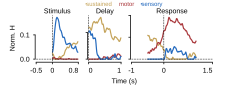

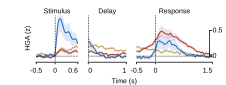

In [2]:
# Figure 2 display settings; fitting windows and cached data stay unchanged.
import seaborn as sns
from matplotlib.ticker import FuncFormatter
FIG2_TEMPORAL_SIZE = (8*cm, 3*cm)
FIG2_TEMPORAL_MARGINS = dict(left=.16, right=.94, wspace=.2, bottom=.28, top=.82)
FIG2_NMF_XLIMS = {'stimulus':(-.5,.8), 'delay':(0.,1.), 'response':(-1.,1.5)}
FIG2_NMF_XTICKS = {'stimulus':(-.5,0.,.8), 'delay':(0.,1.), 'response':(-1.,0.,1.5)}
FIG2_HGA_XLIMS = {'stimulus':(-.5,.6), 'delay':(0.,1.), 'response':(-.5,1.5)}
FIG2_HGA_XTICKS = {'stimulus':(-.5,0.,.6), 'delay':(0.,1.), 'response':(-.5,0.,1.5)}
temporal_layouts = []

def fig2_temporal_axes(windows):
    fig = plt.figure(figsize=FIG2_TEMPORAL_SIZE)
    gs = fig.add_gridspec(1, len(windows),
        width_ratios=[hi-lo for lo,hi in windows.values()], **FIG2_TEMPORAL_MARGINS)
    axes = [fig.add_subplot(gs[0,j]) for j in range(len(windows))]
    return fig, axes

def style_fig2_temporal(fig, axes, windows, ticks, ylabel, hga=False):
    for ax,(phase,window) in zip(axes, windows.items()):
        ax.set_xlim(window)
        ax.set_xticks(ticks[phase])
        ax.set_xlabel('')
        ax.set_title(phase.capitalize(), fontsize=7, pad=2)
        ax.axvline(0, color='k', ls='--', lw=.5, clip_on=False)
        ax.axhline(0, color='k', ls='--', lw=.5, clip_on=False)
        ax.tick_params(labelsize=7, width=.75, length=2, which='both')
        plt.setp(ax.spines.values(), linewidth=.75)
        sns.despine(ax=ax, offset=1, trim=True)
        if ax is not axes[0]: ax.set_yticklabels([])
        ax.set_ylabel(ylabel if ax is axes[0] else '', fontsize=7)
        # Keep neighboring endpoint labels inside their own phase columns.
        ax.xaxis.set_major_formatter(FuncFormatter(lambda value, pos: f'{value:g}'))
        labels=ax.get_xticklabels()
        labels[0].set_ha('center' if window[0]<0 else 'left')
        labels[-1].set_ha('right')
        if hga:
            ax.set_yticks([])
            ax.spines['left'].set_visible(False)
            ax.set_ylim(-.1,.8)
    if hga:
        ax=axes[-1]
        lo,hi=ax.get_xlim(); span=hi-lo
        xbar=hi-.04*span; cap=.03*span
        ax.plot([xbar,xbar],[0.,.5],c='k',lw=.75,clip_on=False)
        for y,label in [(0.,'0'),(.5,'0.5')]:
            ax.plot([xbar,xbar+cap],[y,y],c='k',lw=.75,clip_on=False)
            ax.text(xbar+1.4*cap,y,label,fontsize=7,va='center',ha='left')
    else:
        # Response now contains pre-onset data: keep labels above all curves.
        handles,labels=axes[-1].get_legend_handles_labels()
        fig.legend(handles,labels,fontsize=6,loc='upper center',
            bbox_to_anchor=(.55,.98),ncol=3,frameon=False,handlelength=0,
            handletextpad=0,borderpad=0,borderaxespad=0,columnspacing=1.2,
            labelcolor='linecolor')
    fig.text(.55,.08,'Time (s)',ha='center',va='top',fontsize=7)

def save_fig2_temporal(fig, axes, filename, windows):
    # Match save_aligned_svg in vizpub/fig2.ipynb: never tight-crop the canvas.
    path=(FIG/filename).resolve()
    assert path.is_relative_to(FIG.resolve())
    fig.canvas.draw()
    renderer=fig.canvas.get_renderer()
    labels=[t for ax in axes for t in ax.get_xticklabels() if t.get_visible()]
    boxes=[t.get_window_extent(renderer) for t in labels]
    for i,a in enumerate(boxes):
        for b in boxes[i+1:]:
            assert min(a.x1,b.x1)-max(a.x0,b.x0)<.1, 'Overlapping phase tick labels'
    title_texts=[ax.title for ax in axes]+[t for legend in fig.legends for t in legend.get_texts()]
    text_boxes=[t.get_window_extent(renderer) for t in title_texts]
    for a in text_boxes:
        assert a.y0>=0 and a.y1<=fig.bbox.y1 and a.x0>=0 and a.x1<=fig.bbox.x1, 'Clipped header'
    for i,a in enumerate(text_boxes):
        for b in text_boxes[i+1:]:
            assert min(a.x1,b.x1)<=max(a.x0,b.x0) or min(a.y1,b.y1)<=max(a.y0,b.y0), 'Overlapping header'
    temporal_layouts.append(dict(filename=filename, windows=windows,
        figsize_cm=[float(x/cm) for x in fig.get_size_inches()],
        axes_bounds=[list(ax.get_position().bounds) for ax in axes],
        xlims=[list(ax.get_xlim()) for ax in axes],
        ylims=[list(ax.get_ylim()) for ax in axes],
        xticks=[list(ax.get_xticks()) for ax in axes]))
    fig.savefig(path, format='svg', bbox_inches=None, pad_inches=0)
    plt.close(fig)
    return path

def template_panel(include_reference=False):
    h=pd.read_csv(OUT/'H_by_phase.csv')
    reference=pd.read_csv(CANONICAL/'H_by_phase.csv') if include_reference else None
    fig,axes=fig2_temporal_axes(FIG2_NMF_XLIMS)
    for ax,(phase,window) in zip(axes, FIG2_NMF_XLIMS.items()):
        for name in COMPONENTS:
            d=h.loc[h.phase.eq(phase)&h.functional_cluster.eq(name)&h.time.between(*window)].sort_values('time')
            ax.plot(d.time,d.normalized_H,color=FUNCTION_COLORS[name],lw=1.2,label=CLUSTER_LABELS[name])
            if include_reference:
                d=reference.loc[reference.phase.eq(phase)&reference.functional_cluster.eq(name)&reference.time.between(*window)].sort_values('time')
                ax.plot(d.time,d.normalized_H,color=FUNCTION_COLORS[name],lw=.8,ls='--',alpha=.65)
    style_fig2_temporal(fig,axes,FIG2_NMF_XLIMS,FIG2_NMF_XTICKS,'Norm. H')
    name='nmf_temporal_comparison.svg' if include_reference else 'insula_nmf_temporal.svg'
    return save_fig2_temporal(fig,axes,name,FIG2_NMF_XLIMS)

template_panel()
template_panel(True)

# Full pipeline computes the same subject-balanced summary; redraws read its cache.
if globals().get('TEMPORAL_REDRAW_ONLY', False):
    summary=pd.read_csv(OUT/'insula_hga_time_summary.csv')
else:
    empirical = insula_rows.merge(assignments[['channel','functional_cluster']],on='channel',validate='many_to_one')
    electrode_means = empirical.groupby(['subject','channel','functional_cluster','phase','time'],observed=True).value.mean().reset_index()
    subject_means = electrode_means.groupby(['subject','functional_cluster','phase','time'],observed=True).value.mean().reset_index()
    subject_means.to_csv(OUT/'insula_hga_subject_means.csv', index=False)
    summary = subject_means.groupby(['functional_cluster','phase','time'],observed=True).value.agg(['mean','sem','count']).reset_index()
    summary.to_csv(OUT/'insula_hga_time_summary.csv',index=False)

fig,axes=fig2_temporal_axes(FIG2_HGA_XLIMS)
for ax,(phase,window) in zip(axes,FIG2_HGA_XLIMS.items()):
    for name in COMPONENTS:
        d=summary.loc[summary.phase.eq(phase)&summary.functional_cluster.eq(name)&summary.time.between(*window)].sort_values('time')
        ax.plot(d.time,d['mean'],color=FUNCTION_COLORS[name],lw=1)
        ax.fill_between(d.time,(d['mean']-d['sem']).to_numpy(),(d['mean']+d['sem']).to_numpy(),color=FUNCTION_COLORS[name],alpha=.15,lw=0)
style_fig2_temporal(fig,axes,FIG2_HGA_XLIMS,FIG2_HGA_XTICKS,'HGA (z)',hga=True)
save_fig2_temporal(fig,axes,'insula_hga_temporal.svg',FIG2_HGA_XLIMS)
display(SVG(filename=str(FIG/'insula_nmf_temporal.svg')))
display(SVG(filename=str(FIG/'insula_hga_temporal.svg')))


## 4. Recompute whole-brain projection in the same 30 participants
Fit nonnegative electrode weights onto the **new** H, using the original mask-any
selection and complete-phase rules. This is waveform similarity, not connectivity.
Save waveform matrices to support auditable empirical time courses and reconstruction QC.

In [5]:
projection_tables=[]; projection_X=[]; reconstruction_X=[]; projection_detail={}
for subject in selected_subjects:
    print('Projecting',subject,flush=True)
    rows,used_paths,missing_inputs=wb.load_subject_hga_rows(subject,TASKS,PHASES,results_root=ROOT/'results')
    raw,meta=wb.build_subject_waveform_matrix(rows,new_basis,significance_mode='mask-any',min_coverage=.95,min_tasks=1)
    Xsub,keep=wa.prepare_shape_matrix(raw.to_numpy(float))
    meta=meta.iloc[np.flatnonzero(keep)]
    weights,reconstructed=wb.project_fixed_temporal_basis(Xsub,new_basis.H,ridge=0)
    table=wb.build_projection_table(meta,Xsub,weights,reconstructed,COMPONENTS,pilot_min_explained_energy=.5)
    table.insert(1,'significance_mode','mask-any')
    table.insert(2,'in_discovery',table.channel.isin(selected_channels))
    assert np.isfinite(Xsub).all() and np.isfinite(weights).all() and (weights>=0).all()
    table.to_csv(PROJ/f'sub-{subject}_projection.csv',index=False)
    projection_tables.append(table); projection_X.append(Xsub); reconstruction_X.append(reconstructed)
    projection_detail[subject]={'n_electrodes':len(table),'input_paths':used_paths,'missing_inputs':missing_inputs}
    del rows,raw,meta
projection=pd.concat(projection_tables,ignore_index=True)
projection.to_csv(PROJ/'electrode_projection.csv',index=False)
all_X=np.vstack(projection_X); all_reconstructed=np.vstack(reconstruction_X)
np.savez_compressed(PROJ/'waveforms.npz',X=all_X,reconstructed=all_reconstructed,channels=projection.channel.to_numpy(dtype=str))
assert set(projection.subject)==set(selected_subjects)
projection_manifest={'method':'fixed_temporal_basis_nnls','subjects':selected_subjects,'subjects_used':selected_subjects,
    'n_subjects_used':N_SUBJECTS,'n_electrodes':len(projection),'basis_path':str(OUT/'H_by_phase.csv'),
    'basis_sha256':digest(OUT/'H_by_phase.csv'),'cohort_sha256':cohort_hash,'subjects_detail':projection_detail,
    'significance_mode':'mask-any','min_coverage':.95,'min_tasks':1,'ridge':0,'tasks':TASKS,'phases':PHASES,'fit_windows':WINDOWS,
    'interpretation':'waveform motif projection, not connectivity'}
json_save(PROJ/'manifest.json',projection_manifest)
prepared=wv.prepare_projection_frame(projection)
prepared.to_csv(PROJ/'heldout_projection_scores.csv',index=False)
assert set(prepared.subject)==set(selected_subjects)
print('Projection:',len(projection),'electrodes; spatial input:',len(prepared),'electrodes from',prepared.subject.nunique(),'subjects',flush=True)
# Held-out observed time courses are grouped by dominant motif, not by thresholded surface vertices.
lookup=pd.Series(np.arange(len(projection)),index=projection.channel)
time_rows=[]
for (subject,name),group in prepared.groupby(['subject','best_component'],sort=True):
    idx=lookup.loc[group.channel].to_numpy()
    observed=all_X[idx].mean(axis=0); rebuilt=all_reconstructed[idx].mean(axis=0)
    for phase,sl in phase_slices.items():
        time_rows.extend({'subject':subject,'functional_cluster':name,'phase':phase,'time':float(t),
                         'observed':float(y),'reconstructed':float(z),'n_electrodes':len(idx)}
                        for t,y,z in zip(new_basis.phase_times[phase],observed[sl],rebuilt[sl]))
wb_times=pd.DataFrame(time_rows)
wb_times.to_csv(PROJ/'heldout_subject_timecourses.csv',index=False)
wb_summary=wb_times.groupby(['functional_cluster','phase','time']).agg(mean=('observed','mean'),sem=('observed','sem'),
    n_subjects=('observed','count'),reconstructed=('reconstructed','mean')).reset_index()
wb_summary.to_csv(PROJ/'heldout_timecourse_summary.csv',index=False)


Projecting D0071


Projecting D0137


Projecting D0103


Projecting D0107


Projecting D0129


Projecting D0080


... (21 outputs left out)

Projecting D0093


Projecting D0060


Projecting D0022


Projection: 3564 electrodes; spatial input: 1886 electrodes from 30 subjects


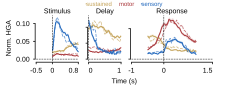

4769

In [3]:
# Observed normalized positive HGA ± subject SEM; dashed lines are reconstruction.
# These cached waveforms exist only within the current fitting windows, including Response (-0.5, 1.0).
wb_summary=pd.read_csv(PROJ/'heldout_timecourse_summary.csv')
fig,axes=fig2_temporal_axes(FIG2_NMF_XLIMS)
for ax,(phase,window) in zip(axes,FIG2_NMF_XLIMS.items()):
    for name in COMPONENTS:
        d=wb_summary.loc[wb_summary.phase.eq(phase)&wb_summary.functional_cluster.eq(name)&wb_summary.time.between(*window)].sort_values('time')
        ax.plot(d.time,d['mean'],color=FUNCTION_COLORS[name],label=CLUSTER_LABELS[name],lw=1)
        ax.fill_between(d.time,(d['mean']-d['sem']).to_numpy(),(d['mean']+d['sem']).to_numpy(),color=FUNCTION_COLORS[name],alpha=.15,lw=0)
        ax.plot(d.time,d.reconstructed,color=FUNCTION_COLORS[name],ls='--',lw=.8,alpha=.7)
style_fig2_temporal(fig,axes,FIG2_NMF_XLIMS,FIG2_NMF_XTICKS,'Norm. HGA')
save_fig2_temporal(fig,axes,'wholebrain_temporal.svg',FIG2_NMF_XLIMS)
display(SVG(filename=str(FIG/'wholebrain_temporal.svg')))
(OUT/'temporal_layouts.json').write_text(json.dumps(temporal_layouts,indent=2))


## 5. Insula spatial weights — approved Figure 2 style
The rendering helpers below are copied from `vizpub/fig2.ipynb`, so this notebook
contains the entire figure implementation and does not execute another notebook.
Gaussian sigma=5 mm, nearest-electrode cutoff=6 mm, visible density >40% of each
component/hemisphere peak, matching the approved Figure 2 version.

In [7]:
import os
import warnings

import mne
import pyvista as pv
from matplotlib.lines import Line2D
from matplotlib.path import Path as MplPath
from mne.viz import Brain
from scipy.ndimage import gaussian_filter
from scipy.spatial import cKDTree

os.environ.setdefault("PYVISTA_OFF_SCREEN", "true")
pv.OFF_SCREEN = True
mne.viz.set_3d_backend("notebook")

recon_dir = "/cwork/ns458/ECoG_Recon/"
template = "cvs_avg35_inMNI152"
insula_patterns = (
    "G_insular_short",
    "G_Ins_lg_and_S_cent_ins",
    "S_circular_insula_ant",
    "S_circular_insula_inf",
    "S_circular_insula_sup",
)
POINT_SIZE = 10.0
KDE_BANDWIDTH_PX = 25.0
KDE_LEVEL_FRAC = 0.18
KDE_FILL_ALPHA = 0.12
KDE_MIN_POINTS = 2
CROP_PAD_PX = 24
INSULA_COLOR = (0.9, 0.9, 0.9)
INSULA_LABEL_ALPHA = 0.55

labels = mne.read_labels_from_annot(
    subject=template,
    parc="aparc.a2009s",
    surf_name="pial",
    hemi="both",
    subjects_dir=recon_dir,
)
lh_pial_coords, lh_faces = mne.read_surface(f"{recon_dir}/{template}/surf/lh.pial")
rh_pial_coords, rh_faces = mne.read_surface(f"{recon_dir}/{template}/surf/rh.pial")
lh_tree = cKDTree(lh_pial_coords)
rh_tree = cKDTree(rh_pial_coords)


def _insula_vertices(hemi: str) -> np.ndarray:
    verts = []
    for lab in labels:
        if lab.hemi == hemi and any(p in lab.name for p in insula_patterns):
            verts.extend(lab.vertices)
    if not verts:
        raise RuntimeError(f"No insula labels for {hemi}")
    return np.unique(verts)


def _faces_to_polydata(coords, faces) -> pv.PolyData:
    faces_pv = np.hstack(
        [np.full((len(faces), 1), 3, dtype=np.int64), np.asarray(faces, dtype=np.int64)]
    ).ravel()
    return pv.PolyData(np.asarray(coords, dtype=float), faces_pv)


def insula_mesh(hemi: str, pial: np.ndarray, faces: np.ndarray):
    verts = _insula_vertices(hemi)
    keep = np.all(np.isin(faces, verts), axis=1)
    mesh = _faces_to_polydata(pial, faces[keep])
    center = pial[verts].mean(axis=0)
    return mesh, center


lh_insula, lh_insula_center = insula_mesh("lh", lh_pial_coords, lh_faces)
rh_insula, rh_insula_center = insula_mesh("rh", rh_pial_coords, rh_faces)

Using notebook 3d backend.


Reading labels from parcellation...


   read 75 labels from /cwork/ns458/ECoG_Recon/cvs_avg35_inMNI152/label/lh.aparc.a2009s.annot


   read 75 labels from /cwork/ns458/ECoG_Recon/cvs_avg35_inMNI152/label/rh.aparc.a2009s.annot


In [8]:
import matplotlib.colors as mcolors
from matplotlib.backends.backend_agg import FigureCanvasAgg
from matplotlib.figure import Figure
from matplotlib.patches import Patch
from scipy import ndimage
from scipy.spatial.distance import cdist

# Gaussian density and display parameters ported from notebooks/nmf_weight_density.ipynb.
DENSITY_BANDWIDTH = 5.0       # mm; Gaussian kernel sigma
DENSITY_MAX_DISTANCE = 6.0    # mm; zero density beyond nearest electrode
DENSITY_VISIBLE_FRACTION = 0.40  # retain each component × hemisphere density core
DENSITY_COLOR_VMAX_PERCENTILE = 99.0
WEIGHT_DENSITY_COMPONENTS = ("sensory", "sustain", "motor")
WEIGHT_DENSITY_LOADING_COLS = {
    name: f"loading_{name}" for name in WEIGHT_DENSITY_COMPONENTS
}

# The envelope is extracted from the already-thresholded rendered overlay.
WEIGHT_DENSITY_ENVELOPE_MIN_COLOR_SIGNAL = 0.03
WEIGHT_DENSITY_ENVELOPE_CLOSE_RADIUS_PX = 18
WEIGHT_DENSITY_ENVELOPE_MIN_AREA_PX = 120
WEIGHT_DENSITY_ENVELOPE_SMOOTH_SIGMA_PX = 7.0
WEIGHT_DENSITY_ENVELOPE_LINE_WIDTH_PX = 1.4
WEIGHT_DENSITY_ENVELOPE_COLOR = "#222222"

In [9]:
def crop_to_content(img, xy, pad=CROP_PAD_PX):
    rgb = np.asarray(img)
    mask = np.any(rgb < 250, axis=2)
    if not mask.any():
        return rgb, np.asarray(xy, dtype=float)
    ys, xs = np.nonzero(mask)
    y0 = max(0, int(ys.min()) - pad)
    y1 = min(rgb.shape[0], int(ys.max()) + 1 + pad)
    x0 = max(0, int(xs.min()) - pad)
    x1 = min(rgb.shape[1], int(xs.max()) + 1 + pad)
    xy_c = np.asarray(xy, dtype=float).copy()
    if xy_c.size:
        xy_c[:, 0] -= x0
        xy_c[:, 1] -= y0
    return rgb[y0:y1, x0:x1], xy_c

def weight_density_make_insula_brain(hemi: str):
    """Hide the whole cortex; the insula is added as one standalone mesh below."""
    return Brain(
        template,
        subjects_dir=recon_dir,
        surf="pial",
        hemi=hemi,
        background="white",
        show=False,
        cortex=INSULA_COLOR,
        alpha=0.0,
        size=(800, 800),
    )


def weight_density_compute(
    surface_coords: np.ndarray,
    electrode_coords: np.ndarray,
    electrode_weights: np.ndarray,
    *,
    bandwidth: float = DENSITY_BANDWIDTH,
    max_distance: float = DENSITY_MAX_DISTANCE,
) -> np.ndarray:
    """Gaussian pial-surface density for one continuous NMF loading."""
    density = np.zeros(len(surface_coords), dtype=float)
    if len(electrode_coords) == 0:
        return density
    weights = np.clip(np.asarray(electrode_weights, dtype=float), 0.0, None)
    distances = cdist(surface_coords, electrode_coords)
    near = distances.min(axis=1) < max_distance
    if near.any():
        kernel = np.exp(-distances[near] ** 2 / (2.0 * bandwidth ** 2))
        density[near] = kernel @ weights
    return density


def weight_density_to_rgba(
    density: np.ndarray,
    color_rgb: np.ndarray,
    *,
    visible_fraction: float = DENSITY_VISIBLE_FRACTION,
    vmax_percentile: float = DENSITY_COLOR_VMAX_PERCENTILE,
) -> np.ndarray:
    """Per-vertex RGBA for one insula mesh.

    Below threshold, vertices retain the translucent gray insula style. Above
    threshold, RGB is the pure component color and alpha follows a full-range
    smoothstep from the threshold to the robust density maximum.
    """
    if not 0.0 <= visible_fraction < 1.0:
        raise ValueError("visible_fraction must be in [0, 1)")
    if not 0.0 < vmax_percentile <= 100.0:
        raise ValueError("vmax_percentile must be in (0, 100]")
    density = np.nan_to_num(
        np.asarray(density, dtype=float), nan=0.0, posinf=0.0, neginf=0.0
    )
    n = len(density)
    rgba = np.empty((n, 4), dtype=float)
    rgba[:, :3] = np.asarray(INSULA_COLOR, dtype=float)
    rgba[:, 3] = float(INSULA_LABEL_ALPHA)
    positive = density > 0
    if positive.any():
        peak = float(np.max(density[positive]))
        threshold = visible_fraction * peak
        vmax = float(np.percentile(density[positive], vmax_percentile))
        vmax = max(vmax, threshold + np.finfo(float).eps * max(peak, 1.0))
        scaled = np.clip((density - threshold) / (vmax - threshold), 0.0, 1.0)
        alpha = scaled * scaled * (3.0 - 2.0 * scaled)
        visible = density >= threshold
        rgba[visible, :3] = np.asarray(color_rgb, dtype=float)
        rgba[visible, 3] = alpha[visible]
    return rgba


def weight_density_add_insula_mesh(brain, hemi: str, vertex_rgba: np.ndarray) -> None:
    """Add one lit insula mesh with per-vertex density RGBA."""
    mesh = (lh_insula if hemi == "lh" else rh_insula).copy(deep=True)
    mesh["rgba"] = (np.clip(vertex_rgba, 0.0, 1.0) * 255.0).astype(np.uint8)
    brain._renderer.plotter.add_mesh(
        mesh,
        scalars="rgba",
        rgba=True,
        lighting=True,
        smooth_shading=True,
    )


def weight_density_color_signal(img: np.ndarray, color_rgb: np.ndarray) -> np.ndarray:
    """Estimate overlay alpha from chroma while rejecting white/gray cortex."""
    pixels = np.asarray(img)
    rgb = pixels[:, :, :3].astype(float) / 255.0
    target = np.asarray(color_rgb, dtype=float)
    target_chroma = target - target.mean()
    denom = float(np.dot(target_chroma, target_chroma))
    if denom <= 1e-12:
        return np.zeros(rgb.shape[:2], dtype=float)
    pixel_chroma = rgb - rgb.mean(axis=2, keepdims=True)
    signal = np.tensordot(pixel_chroma, target_chroma, axes=([2], [0])) / denom
    if pixels.shape[2] == 4:
        signal *= pixels[:, :, 3].astype(float) / 255.0
    return np.clip(signal, 0.0, 1.0)


def weight_density_disk(radius: int) -> np.ndarray:
    radius = max(0, int(radius))
    yy, xx = np.ogrid[-radius : radius + 1, -radius : radius + 1]
    return (xx * xx + yy * yy) <= radius * radius


def weight_density_dominant_mask(signal: np.ndarray) -> np.ndarray | None:
    peak = float(np.max(signal)) if signal.size else 0.0
    if peak < WEIGHT_DENSITY_ENVELOPE_MIN_COLOR_SIGNAL:
        return None
    # Gray below-threshold vertices have negligible component chroma.
    mask = signal >= WEIGHT_DENSITY_ENVELOPE_MIN_COLOR_SIGNAL
    mask = ndimage.binary_closing(
        mask,
        structure=weight_density_disk(WEIGHT_DENSITY_ENVELOPE_CLOSE_RADIUS_PX),
    )
    mask = ndimage.binary_fill_holes(mask)
    labels_2d, count = ndimage.label(mask)
    if count == 0:
        return None
    areas = np.bincount(labels_2d.ravel(), minlength=count + 1)
    masses = np.bincount(
        labels_2d.ravel(), weights=signal.ravel(), minlength=count + 1
    )
    valid = np.flatnonzero(areas >= WEIGHT_DENSITY_ENVELOPE_MIN_AREA_PX)
    valid = valid[valid != 0]
    if len(valid) == 0:
        return None
    main_label = int(valid[np.argmax(masses[valid])])
    return ndimage.binary_fill_holes(labels_2d == main_label)


def weight_density_smooth_envelope(mask: np.ndarray) -> np.ndarray | None:
    smooth = ndimage.gaussian_filter(
        np.pad(mask.astype(float), 1),
        sigma=WEIGHT_DENSITY_ENVELOPE_SMOOTH_SIGMA_PX,
    )
    tmp_fig = Figure()
    tmp_ax = tmp_fig.subplots()
    contour_set = tmp_ax.contour(smooth, levels=[0.5])
    paths = [segment - 1.0 for segment in contour_set.allsegs[0] if len(segment) >= 4]
    if not paths:
        return None

    def polygon_area(points: np.ndarray) -> float:
        x, y = points[:, 0], points[:, 1]
        return 0.5 * abs(np.dot(x, np.roll(y, 1)) - np.dot(y, np.roll(x, 1)))

    return max(paths, key=polygon_area)


def weight_density_add_envelope(img: np.ndarray, color_rgb: np.ndarray) -> np.ndarray:
    signal = weight_density_color_signal(img, color_rgb)
    mask = weight_density_dominant_mask(signal)
    if mask is None:
        return np.asarray(img)
    envelope = weight_density_smooth_envelope(mask)
    if envelope is None:
        return np.asarray(img)

    rgb = np.asarray(img)[:, :, :3]
    height, width = rgb.shape[:2]
    dpi = 100
    fig = Figure(figsize=(width / dpi, height / dpi), dpi=dpi, facecolor="white")
    canvas = FigureCanvasAgg(fig)
    ax = fig.add_axes([0, 0, 1, 1], facecolor="white")
    ax.imshow(rgb, interpolation="nearest")
    ax.plot(
        envelope[:, 0],
        envelope[:, 1],
        color=WEIGHT_DENSITY_ENVELOPE_COLOR,
        linewidth=WEIGHT_DENSITY_ENVELOPE_LINE_WIDTH_PX * 72.0 / dpi,
        solid_capstyle="round",
        solid_joinstyle="round",
    )
    ax.set_xlim(-0.5, width - 0.5)
    ax.set_ylim(height - 0.5, -0.5)
    ax.axis("off")
    canvas.draw()
    return np.asarray(canvas.buffer_rgba())[:, :, :3].copy()


def weight_density_crop(img: np.ndarray, pad: int = CROP_PAD_PX) -> np.ndarray:
    """Crop the RGB brain plus envelope together, preserving their alignment."""
    cropped, _ = crop_to_content(
        np.asarray(img)[:, :, :3], np.empty((0, 2), dtype=float), pad=pad
    )
    return cropped


def weight_density_render_hemi(
    hemi: str,
    coords: np.ndarray,
    weights: np.ndarray,
    color_hex: str,
) -> np.ndarray:
    brain = weight_density_make_insula_brain(hemi)
    insula = lh_insula if hemi == "lh" else rh_insula
    density = weight_density_compute(np.asarray(insula.points), coords, weights)
    color_rgb = np.asarray(mcolors.to_rgb(color_hex))
    vertex_rgba = weight_density_to_rgba(density, color_rgb)
    weight_density_add_insula_mesh(brain, hemi, vertex_rgba)
    center = lh_insula_center if hemi == "lh" else rh_insula_center
    brain.show_view(
        azimuth=180 if hemi == "lh" else 0,
        elevation=90,
        distance=180,
        focalpoint=center,
    )
    for _ in range(3):
        brain._renderer.plotter.render()
    img = np.asarray(brain.screenshot(mode="rgb"))
    brain.close()
    img = weight_density_add_envelope(img, color_rgb)
    return weight_density_crop(img)

Wrote /hpc/group/coganlab/nanlinshi/insula-functional/img/grant_nmf_30subjects/insula_nmf_weight_density_sensory.svg


Wrote /hpc/group/coganlab/nanlinshi/insula-functional/img/grant_nmf_30subjects/insula_nmf_weight_density_sustain.svg


Wrote /hpc/group/coganlab/nanlinshi/insula-functional/img/grant_nmf_30subjects/insula_nmf_weight_density_motor.svg


Wrote /hpc/group/coganlab/nanlinshi/insula-functional/img/grant_nmf_30subjects/insula_nmf_weight_density_all.svg


/hpc/home/ns458/coganlab/nanlinshi/tmp/ipykernel_1915258/3691824983.py:93: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


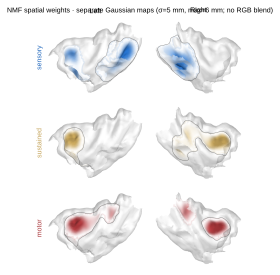

In [10]:
weight_density_frame = assignments.copy()
weight_density_coords = weight_density_frame[["x", "y", "z"]].to_numpy(float)
weight_density_mask_lh = weight_density_coords[:, 0] < 0
weight_density_mask_rh = weight_density_coords[:, 0] > 0
weight_density_images = {}

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for name in WEIGHT_DENSITY_COMPONENTS:
        weights = weight_density_frame[WEIGHT_DENSITY_LOADING_COLS[name]].to_numpy(float)
        color = FUNCTION_COLORS[name]
        lh_img = weight_density_render_hemi(
            "lh",
            weight_density_coords[weight_density_mask_lh],
            weights[weight_density_mask_lh],
            color,
        )
        rh_img = weight_density_render_hemi(
            "rh",
            weight_density_coords[weight_density_mask_rh],
            weights[weight_density_mask_rh],
            color,
        )
        weight_density_images[name] = (lh_img, rh_img)

        fig, axes = plt.subplots(1, 2, figsize=(8 * cm, 3.5 * cm))
        axes[0].imshow(lh_img)
        axes[0].axis("off")
        axes[0].set_title("Left", fontsize=fontsize)
        axes[1].imshow(rh_img)
        axes[1].axis("off")
        axes[1].set_title("Right", fontsize=fontsize)
        axes[0].legend(
            handles=[Patch(facecolor=color, label=CLUSTER_LABELS.get(name, name))],
            loc="upper left",
            fontsize=fontsize,
            frameon=False,
        )
        fig.suptitle(
            f"NMF weight density · {CLUSTER_LABELS.get(name, name)} "
            f"(σ={DENSITY_BANDWIDTH:g} mm, max={DENSITY_MAX_DISTANCE:g} mm)",
            fontsize=fontsize,
        )
        fig.subplots_adjust(
            wspace=0.02, left=0.02, right=0.98, top=0.86, bottom=0.02
        )
        out = save_svg(fig, FIG / f"insula_nmf_weight_density_{name}.svg")
        plt.show()
        print("Wrote", out)

fig, axes = plt.subplots(
    len(WEIGHT_DENSITY_COMPONENTS),
    2,
    figsize=(8 * cm, 3.2 * cm * len(WEIGHT_DENSITY_COMPONENTS)),
)
for row, name in enumerate(WEIGHT_DENSITY_COMPONENTS):
    lh_img, rh_img = weight_density_images[name]
    axes[row, 0].imshow(lh_img)
    axes[row, 0].axis("off")
    axes[row, 1].imshow(rh_img)
    axes[row, 1].axis("off")
    if row == 0:
        axes[row, 0].set_title("Left", fontsize=fontsize)
        axes[row, 1].set_title("Right", fontsize=fontsize)
    axes[row, 0].text(
        -0.02,
        0.5,
        CLUSTER_LABELS.get(name, name),
        transform=axes[row, 0].transAxes,
        va="center",
        ha="right",
        fontsize=fontsize,
        color=FUNCTION_COLORS[name],
        rotation=90,
    )

fig.suptitle(
    "NMF spatial weights · separate Gaussian maps "
    f"(σ={DENSITY_BANDWIDTH:g} mm, max={DENSITY_MAX_DISTANCE:g} mm; no RGB blend)",
    fontsize=fontsize,
)
fig.subplots_adjust(
    wspace=0.02,
    hspace=0.08,
    left=0.08,
    right=0.98,
    top=0.94,
    bottom=0.02,
)
weight_density_out_all = save_svg(
    fig, FIG / "insula_nmf_weight_density_all.svg"
)
plt.show()
print("Wrote", weight_density_out_all)
display(SVG(filename=str(FIG / "insula_nmf_weight_density_all.svg")))

## 6. Whole-brain spatial projection — rebuild the surface cache
Use subject-balanced smoothing (sigma=8 mm, radius=15 mm), at least 3 contributing
participants, >=50% positive specificity, the top 50% of eligible vertices, and at
most five connected clusters per component/hemisphere (minimum 20 vertices).
These are the original thresholds, unchanged for this smaller cohort.

In [11]:
from scripts.plot_nmf_whole_brain_projection import plot_focused_surface_maps
CACHE=PROJ/'surface_motif_maps_focused.npz'
plot_focused_surface_maps(prepared, FIG/'wholebrain_component_maps.svg', CACHE,
    bandwidth=8.,max_distance=15.,min_surface_subjects=3,min_positive_fraction=.5,
    surface_quantile=.5,max_clusters=5,min_cluster_vertices=20)
plt.close('all')

Reading labels from parcellation...


   read 34 labels from /cwork/ns458/ECoG_Recon/cvs_avg35_inMNI152/label/lh.aparc.annot


Reading labels from parcellation...


   read 34 labels from /cwork/ns458/ECoG_Recon/cvs_avg35_inMNI152/label/rh.aparc.annot


Wrote /hpc/group/coganlab/nanlinshi/insula-functional/img/grant_nmf_30subjects/wholebrain_component_maps_combined.svg


Reading labels from parcellation...


   read 34 labels from /cwork/ns458/ECoG_Recon/cvs_avg35_inMNI152/label/lh.aparc.annot


Reading labels from parcellation...


   read 34 labels from /cwork/ns458/ECoG_Recon/cvs_avg35_inMNI152/label/rh.aparc.annot


Wrote /hpc/group/coganlab/nanlinshi/insula-functional/img/grant_nmf_30subjects/wholebrain_component_maps_combined_pial.svg


In [12]:
from src.nmf.whole_brain_projection_viz import (
    combined_focused_rgba, offset_vertices_along_normals,
    retain_largest_surface_clusters, surface_label_boundary_edges)
cm = 1 / 2.54
plt.rcParams["svg.fonttype"] = "none"

RECON_DIR = Path("/cwork/ns458/ECoG_Recon")
TEMPLATE_SUBJECT = "cvs_avg35_inMNI152"
COMPONENTS = tuple(CLUSTER_ORDER)
COMPONENT_LABELS = dict(CLUSTER_LABELS)
LANDMARK_ROIS = (
    ("HG", "transversetemporal", "#111111"),
    ("STG", "superiortemporal", "#1B4332"),
    ("PrG", "precentral", "#1D3557"),
    ("PoG", "postcentral", "#6B3F2A"),
    ("Insula", "insula", "#4A4A4A"),
)
OVERLAY_NORMAL_OFFSET_MM = 0.5
OUTLINE_NORMAL_OFFSET_MM = 0.7
KEEP_TOP = 0.50
FOCUSED_MIN_SUBJECTS = 3
FOCUSED_POSITIVE_FRACTION = 0.50
FOCUSED_MAX_CLUSTERS = 5
FOCUSED_MIN_CLUSTER_VERTICES = 20


PIAL=FIG / "wholebrain_surface_motifs_focused_combined_pial_top50.svg"

def add_rgba_overlay(brain, hemi: str, rgba: np.ndarray) -> None:
    import pyvista as pv

    coords = np.asarray(brain.geo[hemi].coords, dtype=float)
    faces = np.asarray(brain.geo[hemi].faces, dtype=np.int64)
    if len(coords) != len(rgba):
        raise ValueError(
            f"{hemi} overlay length {len(rgba)} does not match mesh {len(coords)}"
        )
    visible = np.asarray(rgba[:, 3], dtype=float) > 1e-6
    keep = visible[faces].any(axis=1)
    if not keep.any():
        return
    lifted = offset_vertices_along_normals(coords, faces, OVERLAY_NORMAL_OFFSET_MM)
    cells = np.hstack(
        [np.full((int(keep.sum()), 1), 3, dtype=np.int64), faces[keep]]
    ).ravel()
    mesh = pv.PolyData(lifted, cells)
    mesh["rgba"] = (np.clip(rgba, 0.0, 1.0) * 255.0).astype(np.uint8)
    brain._renderer.plotter.add_mesh(
        mesh,
        scalars="rgba",
        rgba=True,
        lighting=False,
        smooth_shading=True,
    )


def aparc_label_map(hemi: str) -> dict[str, object]:
    import mne

    labels = mne.read_labels_from_annot(
        TEMPLATE_SUBJECT,
        parc="aparc",
        subjects_dir=str(RECON_DIR),
        hemi=hemi,
    )
    return {label.name.rsplit("-", 1)[0]: label for label in labels}


def add_landmark_outlines(brain, hemi: str) -> None:
    import pyvista as pv

    coords = np.asarray(brain.geo[hemi].coords, dtype=float)
    faces = np.asarray(brain.geo[hemi].faces, dtype=np.int64)
    lifted = offset_vertices_along_normals(coords, faces, OUTLINE_NORMAL_OFFSET_MM)
    labels = aparc_label_map(hemi)
    for _, aparc_name, color in LANDMARK_ROIS:
        label = labels.get(aparc_name)
        if label is None:
            continue
        mask = np.zeros(len(coords), dtype=bool)
        vertices = np.asarray(label.vertices, dtype=int)
        valid = (vertices >= 0) & (vertices < len(coords))
        mask[vertices[valid]] = True
        edges = surface_label_boundary_edges(faces, mask)
        if len(edges) == 0:
            continue
        cells = np.empty(len(edges) * 3, dtype=np.int64)
        cells[0::3] = 2
        cells[1::3] = edges[:, 0]
        cells[2::3] = edges[:, 1]
        mesh = pv.PolyData()
        mesh.points = lifted
        mesh.lines = cells
        brain._renderer.plotter.add_mesh(
            mesh,
            color=color,
            line_width=2.4,
            lighting=False,
            render_lines_as_tubes=False,
        )


def render_hemisphere(payload, hemi, thresholds, value_max, surf="pial"):
    import mne
    from mne.viz import Brain

    brain = Brain(
        TEMPLATE_SUBJECT,
        subjects_dir=str(RECON_DIR),
        surf=surf,
        hemi=hemi,
        background="white",
        show=False,
        cortex=(0.88, 0.88, 0.88),
        alpha=1.0,
        size=(550, 450),
    )
    add_rgba_overlay(
        brain,
        hemi,
        combined_focused_rgba(payload, hemi, thresholds, value_max),
    )
    add_landmark_outlines(brain, hemi)
    distance = 450.0 if surf == "pial" else 550.0
    images = {}
    for view in ("lateral", "medial"):
        brain.show_view(view=view, distance=distance)
        images[view] = brain.screenshot(mode="rgb")
    brain.close()
    return images


CORTEX_GRAY = np.array([0.88, 0.88, 0.88])


def overlay_colormap(hex_color, n: int = 256):
    """Match combined_focused_rgba: hue over gray cortex, alpha 0.40→1."""
    import matplotlib.colors as mcolors

    rgb = np.asarray(mcolors.to_rgb(hex_color), dtype=float)
    fraction = np.linspace(0.0, 1.0, n)
    intensity = 0.40 + 0.60 * fraction
    colors = intensity[:, None] * rgb[None, :] + (1.0 - intensity)[:, None] * CORTEX_GRAY
    return mcolors.LinearSegmentedColormap.from_list("motif_overlay", colors)


def refocus_payload(payload, keep_top: float = KEEP_TOP):
    """Rebuild display masks from the cached maps at a new keep-top fraction."""
    import mne

    if not 0.0 < keep_top <= 1.0:
        raise ValueError("keep_top must be in (0, 1]")
    surface_quantile = 1.0 - keep_top
    faces_by_hemi = {}
    for hemi in ("lh", "rh"):
        _, faces = mne.read_surface(
            str(RECON_DIR / TEMPLATE_SUBJECT / "surf" / f"{hemi}.pial")
        )
        faces_by_hemi[hemi] = faces

    thresholds = {}
    for component in COMPONENTS:
        eligible_parts = []
        for hemi in ("lh", "rh"):
            data = np.asarray(payload[f"{hemi}_{component}_specificity"], dtype=float)
            coverage = np.asarray(payload[f"{hemi}_{component}_coverage"])
            positive_fraction = np.asarray(
                payload[f"{hemi}_{component}_positive_fraction"]
            )
            eligible = (
                (coverage >= FOCUSED_MIN_SUBJECTS)
                & (positive_fraction >= FOCUSED_POSITIVE_FRACTION)
                & np.isfinite(data)
                & (data > 0)
            )
            eligible_parts.append(data[eligible])
        combined = np.concatenate(eligible_parts)
        thresholds[component] = (
            float(np.quantile(combined, surface_quantile)) if len(combined) else np.inf
        )
        for hemi in ("lh", "rh"):
            data = np.asarray(payload[f"{hemi}_{component}_specificity"], dtype=float)
            coverage = np.asarray(payload[f"{hemi}_{component}_coverage"])
            positive_fraction = np.asarray(
                payload[f"{hemi}_{component}_positive_fraction"]
            )
            candidate = (
                (coverage >= FOCUSED_MIN_SUBJECTS)
                & (positive_fraction >= FOCUSED_POSITIVE_FRACTION)
                & np.isfinite(data)
                & (data >= thresholds[component])
            )
            payload[f"{hemi}_{component}_display_mask"] = retain_largest_surface_clusters(
                candidate,
                faces_by_hemi[hemi],
                max_clusters=FOCUSED_MAX_CLUSTERS,
                min_vertices=FOCUSED_MIN_CLUSTER_VERTICES,
            )
    payload["display_thresholds"] = np.array(
        [thresholds[name] for name in COMPONENTS]
    )
    return payload, thresholds


def add_specificity_colorbar(fig, vmin: float, vmax: float) -> None:
    import matplotlib.cm as cm
    import matplotlib.colors as mcolors

    axis = fig.add_axes([0.28, 0.155, 0.44, 0.028])
    cmap = overlay_colormap("#222222")
    norm = mcolors.Normalize(vmin=vmin, vmax=max(vmax, vmin + 1e-6))
    handle = cm.ScalarMappable(norm=norm, cmap=cmap)
    handle.set_array([])
    colorbar = fig.colorbar(handle, cax=axis, orientation="horizontal")
    colorbar.set_ticks([vmin, vmax])
    colorbar.set_ticklabels([f"{vmin:.2f}", f"{vmax:.2f}"])
    colorbar.set_label("specificity", fontsize=7, labelpad=2)
    colorbar.ax.tick_params(labelsize=6, width=0.6, length=2)
    colorbar.outline.set_linewidth(0.6)

Reading labels from parcellation...


   read 34 labels from /cwork/ns458/ECoG_Recon/cvs_avg35_inMNI152/label/lh.aparc.annot


Reading labels from parcellation...


   read 34 labels from /cwork/ns458/ECoG_Recon/cvs_avg35_inMNI152/label/rh.aparc.annot


keep top 50% of eligible vertices
per-motif floors: {'sustained': '0.110', 'motor': '0.191', 'sensory': '0.165'}
colorbar 0.110 → 0.500


Wrote /hpc/group/coganlab/nanlinshi/insula-functional/img/grant_nmf_30subjects/wholebrain_surface_motifs_focused_combined_pial_top50.svg


/hpc/home/ns458/coganlab/nanlinshi/tmp/ipykernel_1915258/461478405.py:68: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


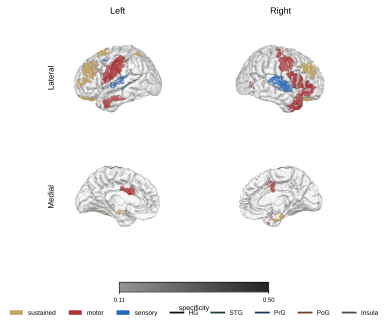

In [13]:
import mne

if not CACHE.exists():
    raise FileNotFoundError(CACHE)

with np.load(CACHE) as raw:
    payload = {key: raw[key] for key in raw.files}
payload, thresholds = refocus_payload(payload, keep_top=KEEP_TOP)
value_max = float(np.asarray(payload["display_value_max"]).reshape(-1)[0])
vmin = float(np.min([thresholds[name] for name in COMPONENTS]))

mne.viz.set_3d_backend("notebook")
views = (("lateral", "Lateral"), ("medial", "Medial"))
hemis = (("lh", "Left"), ("rh", "Right"))
screenshots = {
    hemi: render_hemisphere(payload, hemi, thresholds, value_max, surf="pial")
    for hemi, _ in hemis
}

fig, axes = plt.subplots(2, 2, figsize=(12.0 * cm, 12.4 * cm))
for row, (view, view_label) in enumerate(views):
    for column, (hemi, hemi_label) in enumerate(hemis):
        axes[row, column].imshow(screenshots[hemi][view])
        axes[row, column].axis("off")
        if row == 0:
            axes[row, column].set_title(hemi_label, fontsize=9)
        if column == 0:
            axes[row, column].text(
                0.01,
                0.5,
                view_label,
                transform=axes[row, column].transAxes,
                rotation=90,
                va="center",
                fontsize=8,
            )

fig.subplots_adjust(
    left=0.04, right=0.99, top=0.93, bottom=0.26, wspace=0.02, hspace=0.02
)
add_specificity_colorbar(fig, vmin, value_max)
fig.legend(
    handles=[
        *(
            Patch(facecolor=FUNCTION_COLORS[name], label=CLUSTER_LABELS[name])
            for name in COMPONENTS
        ),
        *(
            Line2D([0], [0], color=color, lw=1.8, label=name)
            for name, _, color in LANDMARK_ROIS
        ),
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, 0.12),
    ncol=8,
    frameon=False,
    fontsize=6.5,
)

print(f"keep top {KEEP_TOP:.0%} of eligible vertices")
print(
    "per-motif floors:",
    {CLUSTER_LABELS[name]: f"{thresholds[name]:.3f}" for name in COMPONENTS},
)
print(f"colorbar {vmin:.3f} → {value_max:.3f}")
save_svg(fig, PIAL, close=False)
print(f"Wrote {PIAL}")
plt.show()
display(SVG(filename=str(PIAL)))

## 7. Validate provenance, cohort identity, and comparison with the original
Similarity metrics are descriptive: the subset was selected using full-cohort information.
We report discrepancies rather than changing the cohort or thresholds to match the old map.

In [14]:
assert len(selected_subjects)==30 and len(set(selected_subjects))==30
assert set(assignments.subject)==set(projection.subject)==set(prepared.subject)==set(selected_subjects)
assert WINDOWS['response']==(-.5,1.) and len(response_times)==191
assert np.any(response_times<0) and np.any(response_times>.5)
assert digest(OUT/'H_by_phase.csv')==projection_manifest['basis_sha256']
assert all(digest(p)==checksum for p,checksum in protected_before.items()), 'Canonical data changed during this run.'
assert np.isfinite(H).all() and np.isfinite(W).all() and (H>=0).all() and (W>=0).all()
# Compare surface specificity on vertices eligible under both cohorts (unchanged thresholds).
with np.load(CANONICAL/'whole_brain_projection/visualization/surface_motif_maps_focused.npz') as z:
    original_payload={k:z[k] for k in z.files}
original_payload,old_thresholds=refocus_payload(original_payload,keep_top=KEEP_TOP)
spatial_comparison=[]
for hemi in ('lh','rh'):
    for name in COMPONENTS:
        prefix=f'{hemi}_{name}'
        a=np.asarray(original_payload[prefix+'_specificity']);b=np.asarray(payload[prefix+'_specificity'])
        covered=(np.asarray(original_payload[prefix+'_coverage'])>=3)&(np.asarray(payload[prefix+'_coverage'])>=3)&np.isfinite(a)&np.isfinite(b)
        ma=np.asarray(original_payload[prefix+'_display_mask'],bool);mb=np.asarray(payload[prefix+'_display_mask'],bool)
        denom=int(ma.sum()+mb.sum())
        spatial_comparison.append({'hemi':hemi,'component':name,'n_shared_vertices':int(covered.sum()),
            'specificity_pearson':float(np.corrcoef(a[covered],b[covered])[0,1]) if covered.sum()>2 else None,
            'display_dice':float(2*np.count_nonzero(ma&mb)/denom) if denom else None,
            'original_visible_vertices':int(ma.sum()),'subset_visible_vertices':int(mb.sum())})
spatial_comparison=pd.DataFrame(spatial_comparison)
spatial_comparison.to_csv(OUT/'wholebrain_surface_comparison.csv',index=False)
required_figures=['insula_nmf_weight_density_all.svg','wholebrain_surface_motifs_focused_combined_pial_top50.svg',
                  'insula_nmf_temporal.svg','insula_hga_temporal.svg','wholebrain_temporal.svg','nmf_temporal_comparison.svg']
import xml.etree.ElementTree as ET
for name in required_figures:
    path=FIG/name
    assert path.is_file() and path.stat().st_size>1000
    assert ET.parse(path).getroot().tag.endswith('svg')
    if 'temporal' in name:
        root=ET.parse(path).getroot()
        np.testing.assert_allclose([float(root.attrib[k].removesuffix('pt'))*2.54/72 for k in ('width','height')],[8,3],atol=1e-6)
        assert 'Go' not in [t.text for t in root.iter('{http://www.w3.org/2000/svg}text')]
validation={'completed_utc':datetime.now(timezone.utc).isoformat(),'n_selected':30,
    'n_insula_subjects':assignments.subject.nunique(),'n_insula_electrodes':len(assignments),
    'n_projection_subjects':projection.subject.nunique(),'n_projection_electrodes':len(projection),
    'n_spatial_subjects':prepared.subject.nunique(),'n_spatial_electrodes':len(prepared),
    'canonical_unchanged':True,'fit_windows':WINDOWS,'response_n_times':len(response_times),'n_features':X.shape[1],'refit':True,'comparison_scope':'canonical comparisons restricted to common phase/time features','template_comparison':comparison.to_dict('records'),
    'raw_label_ari':float(fit_ari),'cluster_counts':assignments.functional_cluster.value_counts().to_dict(),
    'wholebrain_surface_comparison':spatial_comparison.to_dict('records'),
    'figures':{name:digest(FIG/name) for name in required_figures},'cohort_sha256':cohort_hash,
    'disclaimer':'Purposefully selected illustrative subset; not independent validation.'}
json_save(OUT/'validation.json',validation)
display(comparison)
display(spatial_comparison)
print(json.dumps(validation,indent=2,default=lambda v:v.item() if isinstance(v,np.generic) else str(v)),flush=True)

,component,comparison_scope,n_common_features,same_name_cosine,same_name_pearson,best_match
0,sustain,shared phase/time support; not the full extend...,444,0.996396,0.989887,sustain
1,motor,shared phase/time support; not the full extend...,444,0.998378,0.997477,motor
2,sensory,shared phase/time support; not the full extend...,444,0.987557,0.987745,sensory


,hemi,component,n_shared_vertices,specificity_pearson,display_dice,original_visible_vertices,subset_visible_vertices
0,lh,sustain,86853,0.909591,0.597211,16915,12773
1,lh,motor,86853,0.860504,0.531066,11667,7389
2,lh,sensory,86853,0.899498,0.716960,3127,4031
3,rh,sustain,68996,0.869654,0.405751,13635,5076
4,rh,motor,68996,0.844940,0.619792,20533,14866
5,rh,sensory,68996,0.889945,0.777105,3207,3729


{
  "completed_utc": "2026-10-12T19:18:57.236276+00:00",
  "n_selected": 30,
  "n_insula_subjects": 30,
  "n_insula_electrodes": 157,
  "n_projection_subjects": 30,
  "n_projection_electrodes": 3564,
  "n_spatial_subjects": 30,
  "n_spatial_electrodes": 1886,
  "canonical_unchanged": true,
  "fit_windows": {
    "stimulus": [
      0.0,
      1.0
    ],
    "delay": [
      0.0,
      1.0
    ],
    "go": [
      0.0,
      1.0
    ],
    "response": [
      -0.5,
      1.0
    ]
  },
  "response_n_times": 191,
  "n_features": 572,
  "refit": true,
  "comparison_scope": "canonical comparisons restricted to common phase/time features",
  "template_comparison": [
    {
      "component": "sustain",
      "comparison_scope": "shared phase/time support; not the full extended fit",
      "n_common_features": 444,
      "same_name_cosine": 0.9963961016306342,
      "same_name_pearson": 0.9898866202597149,
      "best_match": "sustain"
    },
    {
      "component": "motor",
      "compariso

## Complete Figure 2 replication — frozen 30-subject cohort

Every SVG panel in `vizpub/fig2.ipynb` is reproduced below, using the same 30 subjects and 157 discovery electrodes. The frozen K=3 NMF includes Response −0.5 to 1 s; Go remains in fitting but is omitted from all temporal displays. Display windows and physical canvas sizes follow Figure 2.

Empirical HGA curves use Figure 2's pooled packaged HGA rows and bootstrap 95% confidence intervals (seed 42). These inputs are trial-averaged responses, **not individual trials**. Heatmap rows are bipolar electrodes, with the original significance mask and within-phase onset sorting. The earlier subject-balanced mean ± SEM figure is retained separately.

Rank diagnostics (200 electrode-subsample bootstraps per K=2…6) and PCA are recomputed from the exact cached 157×572 NMF matrix. The diagnostic rank recommendation does not replace the requested fixed K=3 model. Laterality denominators include only these 30 subjects. All additional outputs are isolated under `results/grant_nmf_30subjects/fig2/` and `img/grant_nmf_30subjects/fig2/`.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xarray as xr
from mne_bids import BIDSPath
from tqdm import tqdm

ROOT = Path('/hpc/group/coganlab/nanlinshi/insula-functional')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.nmf.waveform_analysis import CLUSTER_LABELS, CLUSTER_ORDER, FUNCTION_COLORS, ordered_clusters

from src.paths import (
    hga_results_dir,
    img_dir,
    nmf_assignments_path,
    nmf_results_dir,
    save_svg,
)
import json, hashlib, shutil, os
from IPython.display import SVG, display
GRANT_OUT = ROOT / 'results/grant_nmf_30subjects'
FIG2_DATA = GRANT_OUT / 'fig2'
FIG2_DATA.mkdir(exist_ok=True)
SELECTED_SUBJECTS = set(json.loads((GRANT_OUT/'cohort.json').read_text())['subjects'])
assert len(SELECTED_SUBJECTS) == 30
FIG2_PANELS = []


In [2]:
from matplotlib import font_manager
import pathlib

for _ttf in (pathlib.Path(sys.prefix) / "fonts").glob("arial*.ttf"):
    font_manager.fontManager.addfont(str(_ttf))

cm = 1 / 2.54
plt.rcParams["svg.fonttype"] = "none"
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Arial"]

fontsize = 7
fontdict = dict(fontsize=fontsize)

CLUSTERS = list(CLUSTER_ORDER)
HUE_ORDER = [CLUSTER_LABELS[c] for c in CLUSTERS]
PALETTE = [FUNCTION_COLORS[c] for c in CLUSTERS]
CLUSTER_CMAPS = {
    name: sns.light_palette(color, as_cmap=True)
    for name, color in FUNCTION_COLORS.items()
}
LOADING_COLS = [f"loading_{name}" for name in CLUSTERS]
MIXED_SPECIFICITY_MAX = 0.20
MIXED_COLOR = "#6E6E6E"
# Two-way mix: winner − runner-up = 0.20 ⇒ dominance = 0.60.
MIXED_DOMINANCE_REF = 0.5 * (1.0 + MIXED_SPECIFICITY_MAX)


def specificity_from_loadings(loadings: np.ndarray):
    """s_k = max(p_k − max_{j≠k} p_j, 0) with p = loading / sum."""
    loadings = np.clip(np.asarray(loadings, dtype=float), 0.0, None)
    total = loadings.sum(axis=1, keepdims=True)
    proportion = np.divide(
        loadings, total, out=np.zeros_like(loadings), where=total > 0
    )
    spec = np.zeros_like(proportion)
    for k in range(proportion.shape[1]):
        other = np.delete(proportion, k, axis=1)
        spec[:, k] = np.clip(proportion[:, k] - other.max(axis=1), 0.0, None)
    return proportion, spec


def annotate_mixed_assignments(df: pd.DataFrame) -> pd.DataFrame:
    missing = [col for col in LOADING_COLS if col not in df.columns]
    if missing:
        raise KeyError(f"assignments missing {missing}")
    out = df.copy()
    _, spec = specificity_from_loadings(out[LOADING_COLS].to_numpy())
    out["specificity_max"] = spec.max(axis=1)
    out["is_mixed"] = out["specificity_max"] < MIXED_SPECIFICITY_MAX
    return out

TASKS = [
    "PhonemeSequence",
    "LexicalDelay",
    "PictureNaming",
    "SentenceRep",
]
PHASES = ["stimulus", "delay", "go", "response"]
DESCRIPTION = "Repeat"
MODALITY = "sound"
EXCLUDE_SUBJECTS = {"D0121"}

NMF_DIR = FIG2_DATA
NMF_ASSIGNMENTS = GRANT_OUT / 'channel_assignments.csv'
IMG_DIR = ROOT / 'img/grant_nmf_30subjects/fig2'
IMG_DIR.mkdir(exist_ok=True)

# Shared canvas so HGA traces and heatmap columns (especially t=0) align in Illustrator.
FIG2_WIDTH = 3 * len(PHASES) * cm
FIG2_XLIM = (-1.0, 1.0)
FIG2_XTICKS = (-1.0, 0.0, 1.0)
FIG2_MARGINS = dict(left=0.16, right=0.94, wspace=0.2)

# Average / hard-label traces / heatmap: no go column.
TRACE_PHASES = ["stimulus", "delay", "response"]
FIG2_TRACE_SIZE = (8 * cm, 3 * cm)
FIG2_TRACE_XLIMS = {
    "stimulus": (-0.5, 0.6),
    "delay": (0.0, 1.0),
    "response": (-0.5, 1.5),
}
FIG2_TRACE_XTICKS = {
    "stimulus": (-0.5, 0.0, 0.6),
    "delay": (0.0, 1.0),
    "response": (-0.5, 0.0, 1.5),
}


def record_figure(fig, path):
    FIG2_PANELS.append(dict(filename=path.name, canvas_cm=[float(v/cm) for v in fig.get_size_inches()]))
    display(SVG(filename=str(path)))
    return path

_original_save_svg = save_svg

def save_svg(fig, path, **kwargs):
    return record_figure(fig, _original_save_svg(fig, path, **kwargs))

def save_aligned_svg(fig, name):
    from matplotlib.ticker import FuncFormatter
    # Retain reference windows/canvas while preventing adjacent endpoint overlap.
    for ax in fig.axes:
        if len(fig.axes) in (3, 9):
            ax.xaxis.set_major_formatter(FuncFormatter(lambda value, pos: f'{value:g}'))
            labels=ax.get_xticklabels()
            if labels:
                labels[0].set_ha('center' if ax.get_xlim()[0]<0 else 'left')
                labels[-1].set_ha('right')
    path = IMG_DIR / name
    fig.savefig(path, format='svg', bbox_inches=None, pad_inches=0)
    return record_figure(fig, path)


In [3]:
from src.nmf.rank_selection import run_rank_selection
from src.nmf.waveform_pca import fit_waveform_pca

fit_path = GRANT_OUT/'nmf_fit.npz'
fit_hash = hashlib.sha256(fit_path.read_bytes()).hexdigest()
with np.load(fit_path, allow_pickle=True) as cache:
    X_fig2 = cache['X'].copy()
    channels_fig2 = cache['channels'].astype(str)
assert X_fig2.shape == (157, 572)
assign_fig2 = pd.read_csv(NMF_ASSIGNMENTS).set_index('channel').loc[channels_fig2].reset_index()
assert set(assign_fig2.subject) == SELECTED_SUBJECTS
fit_manifest = json.loads((GRANT_OUT/'nmf_manifest.json').read_text())
# Figure H is copied from the frozen refit, never reconstructed from canonical defaults.
shutil.copy2(GRANT_OUT/'H_by_phase.csv', NMF_DIR/'H_by_phase.csv')
cache_key = dict(nmf_sha256=fit_hash, n_boot=200, row_frac=.8, k_min=2, k_max=6,
                 max_iter=5000, random_state=42, n_scree=20)
key_path = NMF_DIR/'diagnostic_cache_key.json'
if not key_path.exists() or json.loads(key_path.read_text()) != cache_key:
    metrics, consensus, decision = run_rank_selection(X_fig2, n_boot=200, row_frac=.8,
        k_min=2, k_max=6, max_iter=5000, random_state=42)
    metrics.to_csv(NMF_DIR/'rank_selection_metrics.csv', index=False)
    decision['fixed_grant_k'] = 3
    (NMF_DIR/'chosen_k.json').write_text(json.dumps(decision, indent=2))
    np.savez_compressed(NMF_DIR/'consensus.npz', **{f'k{k}':v for k,v in consensus.items()})
    pcs, explained = fit_waveform_pca(X_fig2, n_components=20)
    scores = assign_fig2.copy()
    for j in range(pcs.shape[1]): scores[f'PC{j+1}'] = pcs[:,j]
    scores.to_csv(NMF_DIR/'pc_scores.csv', index=False)
    pc_meta = dict(n_embedding_pcs=max(2,int(np.sum(explained>.05))), random_state=42,
        explained_variance_ratio=explained.tolist(), variance_threshold=.05,
        n_electrodes=157, n_features=572, nmf_sha256=fit_hash)
    (NMF_DIR/'pc_clustering_meta.json').write_text(json.dumps(pc_meta,indent=2))
    key_path.write_text(json.dumps(cache_key,indent=2))
print('Diagnostics use frozen matrix:', X_fig2.shape, 'SHA256:', fit_hash)


Diagnostics use frozen matrix: (157, 572) SHA256: 9e3e8c27ccfce97aff820dfc0aaafde5972be79f72c56037c8a7a37b0dd4d32f


## Load assignments and packaged HGA


In [4]:
assignments = pd.read_csv(NMF_ASSIGNMENTS)
assign_map = assignments.set_index("channel")["functional_cluster"]
keep_channels = set(assignments["channel"])

inventory=json.loads((GRANT_OUT/'input_inventory.json').read_text())
hga_paths=[Path(item['path']) for item in inventory]
for item in inventory:
    assert hashlib.sha256(Path(item['path']).read_bytes()).hexdigest()==item['sha256'], item['path']

frames = []
for path in tqdm(hga_paths, desc="load HGA"):
    df = pd.read_csv(path)
    if "channel" not in df.columns:
        continue
    df = df[df["channel"].isin(keep_channels)]
    if not df.empty:
        frames.append(df)

if not frames:
    raise FileNotFoundError(
        f"No HGA rows for NMF channels under results/hga/ for tasks={TASKS}"
    )

HGAs = pd.concat(frames, ignore_index=True)
HGAs.loc[HGAs.phase == "Resp", "phase"] = "Response"
HGAs.loc[HGAs.phase == "Audio", "phase"] = "Stimulus"
HGAs["phase"] = HGAs["phase"].astype(str).str.lower()
HGAs["functional_cluster"] = HGAs["channel"].map(assign_map)

subset = HGAs[
    (HGAs.description == DESCRIPTION)
    & (HGAs.modality == MODALITY)
    & HGAs["functional_cluster"].isin(CLUSTERS)
    & ~HGAs["subject"].isin(EXCLUDE_SUBJECTS)
].copy()
subset["cluster_label"] = subset["functional_cluster"].map(CLUSTER_LABELS)

print("assignments:", NMF_ASSIGNMENTS)
print("assignment clusters:", assignments["functional_cluster"].value_counts().to_dict())
print(subset.groupby("functional_cluster")["channel"].nunique())
print("phases:", sorted(subset.phase.unique()))
print("tasks:", sorted(subset.task.unique()) if "task" in subset.columns else "n/a")
if subset.empty:
    raise ValueError(
        "Hard-label HGA subset is empty. Check cluster names, description, and modality."
    )
assert set(subset.subject) == SELECTED_SUBJECTS
assert set(subset.channel) == set(assignments.channel)

plt.close("all")


load HGA:   0%|          | 0/400 [00:00<?, ?it/s]

load HGA:   1%|▏         | 5/400 [00:00<00:16, 24.16it/s]

load HGA:   2%|▏         | 8/400 [00:00<00:33, 11.60it/s]

load HGA:   2%|▎         | 10/400 [00:00<00:41,  9.37it/s]

load HGA:   3%|▎         | 12/400 [00:01<00:47,  8.11it/s]

load HGA:   3%|▎         | 13/400 [00:01<00:48,  7.91it/s]

... (385 outputs left out)

load HGA: 100%|█████████▉| 399/400 [01:56<00:00,  4.58it/s]

load HGA: 100%|██████████| 400/400 [01:57<00:00,  4.78it/s]

load HGA: 100%|██████████| 400/400 [01:57<00:00,  3.42it/s]

assignments: /hpc/group/coganlab/nanlinshi/insula-functional/results/grant_nmf_30subjects/channel_assignments.csv
assignment clusters: {'motor': 80, 'sustain': 51, 'sensory': 26}
functional_cluster
motor      80
sensory    26
sustain    51
Name: channel, dtype: int64
phases: ['delay', 'go', 'response', 'stimulus']
tasks: ['LexicalDelay', 'PhonemeSequence', 'PictureNaming', 'SentenceRep']


## 1. Average insula HGA

Mean high-gamma across all NMF-assigned insula electrodes, pooled
(not split by cluster). Stimulus / delay / response only (no go).
Same canvas, column widths, and y scale as the hard-label traces.

Seaborn lineplot shows mean ± 95% CI.


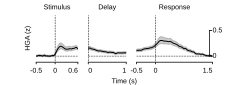

/hpc/home/ns458/coganlab/nanlinshi/tmp/ipykernel_633754/2077091914.py:63: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [5]:
# Pooled insula mean. Same canvas / column widths as hard-label traces. No go.
width_ratios = [hi - lo for lo, hi in (FIG2_TRACE_XLIMS[p] for p in TRACE_PHASES)]
fig = plt.figure(figsize=FIG2_TRACE_SIZE)
gs = fig.add_gridspec(
    nrows=1,
    ncols=len(TRACE_PHASES),
    width_ratios=width_ratios,
    wspace=FIG2_MARGINS["wspace"],
    left=FIG2_MARGINS["left"],
    right=FIG2_MARGINS["right"],
    bottom=0.28,
    top=0.82,
)
axes = [fig.add_subplot(gs[0, j]) for j in range(len(TRACE_PHASES))]

for ax, phase in zip(axes, TRACE_PHASES):
    lo, hi = FIG2_TRACE_XLIMS[phase]
    phase_df = subset[
        (subset.phase == phase) & (subset.time >= lo) & (subset.time <= hi)
    ]
    sns.lineplot(seed=42,
        data=phase_df,
        x="time",
        y="value",
        ax=ax,
        color="k",
        legend=False,
        lw=1,
    )
    ax.set_xlim(lo, hi)
    ax.set_xticks(FIG2_TRACE_XTICKS[phase])
    ax.set_xlabel("")
    ax.set_title(phase.capitalize(), fontsize=fontsize)

for ax in axes:
    ax.axvline(x=0, color="k", linestyle="--", linewidth=0.5, clip_on=False)
    ax.axhline(y=0, color="k", linestyle="--", linewidth=0.5, clip_on=False)
    ax.tick_params(labelsize=fontsize, width=0.75, length=2, which="both")
    plt.setp(ax.spines.values(), linewidth=0.75)
    sns.despine(ax=ax, offset=1, trim=True)
    ax.set_yticklabels([])
    ax.set_yticks([])
    ax.spines["left"].set_visible(False)
    ax.set_ylim(-0.1, 0.8)
    ax.set_ylabel("HGA (z)" if ax is axes[0] else "", fontsize=fontsize)

scale = 0.5
ax = axes[-1]
xmin, xmax = ax.get_xlim()
x_span = xmax - xmin
x_bar = xmax - 0.04 * x_span
cap = 0.03 * x_span
ax.plot([x_bar, x_bar], [0.0, scale], color="k", lw=0.75, clip_on=False)
ax.plot([x_bar, x_bar + cap], [0.0, 0.0], color="k", lw=0.75, clip_on=False)
ax.plot([x_bar, x_bar + cap], [scale, scale], color="k", lw=0.75, clip_on=False)
ax.text(x_bar + 1.4 * cap, 0.0, "0", fontsize=fontsize, va="center", ha="left")
ax.text(x_bar + 1.4 * cap, scale, "0.5", fontsize=fontsize, va="center", ha="left")

xmid = 0.5 * (FIG2_MARGINS["left"] + FIG2_MARGINS["right"])
fig.text(xmid, 0.08, "Time (s)", ha="center", va="top", fontsize=fontsize)

save_aligned_svg(fig, "fig2_insula_average_traces.svg")
plt.show()

plt.close("all")


## 2. NMF traces (normalized H)

Canonical concat-NMF basis waveforms. One curve per cluster, not electrode HGA.


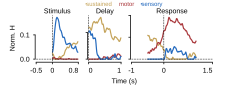

/hpc/home/ns458/coganlab/nanlinshi/tmp/ipykernel_633754/2406739075.py:85: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [6]:
PHASES = TRACE_PHASES.copy()
H_by_phase = pd.read_csv(NMF_DIR / "H_by_phase.csv")
H_by_phase = H_by_phase[H_by_phase["functional_cluster"].isin(CLUSTERS)].copy()
H_by_phase["cluster_label"] = H_by_phase["functional_cluster"].map(CLUSTER_LABELS)
H_by_phase["phase"] = pd.Categorical(
    H_by_phase["phase"], categories=PHASES, ordered=True
)

# Display follows Figure 2, with Go omitted; fitted Response has pre-event data.
FIG2_PHASE_XLIMS = {
    "stimulus": (-0.5, 0.8),
    "delay": (0.0, 1.0),
    "go": (0.0, 1.0),
    "response": (-1.0, 1.5),
}
FIG2_PHASE_XTICKS = {
    "stimulus": (-0.5, 0.0, 0.8),
    "delay": (0.0, 1.0),
    "go": (0.0, 1.0),
    "response": (-1.0, 0.0, 1.5),
}

width_ratios = [hi - lo for lo, hi in (FIG2_PHASE_XLIMS[p] for p in PHASES)]
fig = plt.figure(figsize=(8 * cm, 3 * cm))
gs = fig.add_gridspec(
    nrows=1,
    ncols=len(PHASES),
    width_ratios=width_ratios,
    wspace=FIG2_MARGINS["wspace"],
    left=FIG2_MARGINS["left"],
    right=FIG2_MARGINS["right"],
    bottom=0.28,
    top=0.82,
)
axes = [fig.add_subplot(gs[0, j]) for j in range(len(PHASES))]

for ax, phase in zip(axes, PHASES):
    lo, hi = FIG2_PHASE_XLIMS[phase]
    phase_df = H_by_phase[
        (H_by_phase["phase"] == phase)
        & (H_by_phase["time"] >= lo)
        & (H_by_phase["time"] <= hi)
    ]
    sns.lineplot(
        data=phase_df,
        x="time",
        y="normalized_H",
        hue="cluster_label",
        hue_order=HUE_ORDER,
        ax=ax,
        palette=PALETTE,
        legend=ax is axes[-1],
        lw=1.2,
        errorbar=None,
    )
    ax.set_xlim(lo, hi)
    ax.set_xticks(FIG2_PHASE_XTICKS[phase])
    ax.set_xlabel("")
    ax.set_title(phase.capitalize(), fontsize=fontsize, pad=2)

for ax in axes:
    ax.axvline(x=0, color="k", linestyle="--", linewidth=0.5, clip_on=False)
    ax.axhline(y=0, color="k", linestyle="--", linewidth=0.5, clip_on=False)
    ax.tick_params(labelsize=fontsize, width=0.75, length=2, which="both")
    plt.setp(ax.spines.values(), linewidth=0.75)
    sns.despine(ax=ax, offset=1, trim=True)
    if ax is axes[-1] and ax.get_legend() is not None:
        handles, labels = ax.get_legend_handles_labels()
        ax.get_legend().remove()
        fig.legend(handles, labels, fontsize=6, loc='upper center', bbox_to_anchor=(.55,.98),
                   ncol=3, frameon=False, handlelength=0, handletextpad=0, borderpad=0,
                   borderaxespad=0, columnspacing=1.2, labelcolor='linecolor')
    else:
        leg = ax.get_legend()
        if leg is not None:
            leg.remove()
    if ax is not axes[0]:
        ax.set_yticklabels([])
    ax.set_ylabel("Norm. H" if ax is axes[0] else "", fontsize=fontsize)

xmid = 0.5 * (FIG2_MARGINS["left"] + FIG2_MARGINS["right"])
fig.text(xmid, 0.08, "Time (s)", ha="center", va="top", fontsize=fontsize)

save_aligned_svg(fig, "fig2_nmf_traces.svg")
plt.show()

plt.close("all")


## 3. Hard-label HGA traces

Electrode HGA (`value`) after hard assignment to sustain / motor / sensory.
Seaborn lineplot shows mean ± 95% CI across assigned electrodes.

Stimulus / delay / response only (no go). Same canvas, column widths,
and y scale as the pooled average traces. Shared x label Time (s).


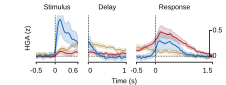

/hpc/home/ns458/coganlab/nanlinshi/tmp/ipykernel_633754/1535737188.py:65: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [7]:
# Same canvas / column widths as the pooled average traces. No go.
width_ratios = [hi - lo for lo, hi in (FIG2_TRACE_XLIMS[p] for p in TRACE_PHASES)]
fig = plt.figure(figsize=FIG2_TRACE_SIZE)
gs = fig.add_gridspec(
    nrows=1,
    ncols=len(TRACE_PHASES),
    width_ratios=width_ratios,
    wspace=FIG2_MARGINS["wspace"],
    left=FIG2_MARGINS["left"],
    right=FIG2_MARGINS["right"],
    bottom=0.28,
    top=0.82,
)
axes = [fig.add_subplot(gs[0, j]) for j in range(len(TRACE_PHASES))]

for ax, phase in zip(axes, TRACE_PHASES):
    lo, hi = FIG2_TRACE_XLIMS[phase]
    phase_df = subset[
        (subset.phase == phase) & (subset.time >= lo) & (subset.time <= hi)
    ]
    sns.lineplot(seed=42,
        data=phase_df,
        x="time",
        y="value",
        hue="cluster_label",
        hue_order=HUE_ORDER,
        ax=ax,
        palette=PALETTE,
        legend=False,
        lw=1,
    )
    ax.set_xlim(lo, hi)
    ax.set_xticks(FIG2_TRACE_XTICKS[phase])
    ax.set_xlabel("")
    ax.set_title(phase.capitalize(), fontsize=fontsize)

for ax in axes:
    ax.axvline(x=0, color="k", linestyle="--", linewidth=0.5, clip_on=False)
    ax.axhline(y=0, color="k", linestyle="--", linewidth=0.5, clip_on=False)
    ax.tick_params(labelsize=fontsize, width=0.75, length=2, which="both")
    plt.setp(ax.spines.values(), linewidth=0.75)
    sns.despine(ax=ax, offset=1, trim=True)
    ax.set_yticklabels([])
    ax.set_yticks([])
    ax.spines["left"].set_visible(False)
    ax.set_ylim(-0.1, 0.8)
    ax.set_ylabel("HGA (z)" if ax is axes[0] else "", fontsize=fontsize)

scale = 0.5
ax = axes[-1]
xmin, xmax = ax.get_xlim()
x_span = xmax - xmin
x_bar = xmax - 0.04 * x_span
cap = 0.03 * x_span
ax.plot([x_bar, x_bar], [0.0, scale], color="k", lw=0.75, clip_on=False)
ax.plot([x_bar, x_bar + cap], [0.0, 0.0], color="k", lw=0.75, clip_on=False)
ax.plot([x_bar, x_bar + cap], [scale, scale], color="k", lw=0.75, clip_on=False)
ax.text(x_bar + 1.4 * cap, 0.0, "0", fontsize=fontsize, va="center", ha="left")
ax.text(x_bar + 1.4 * cap, scale, "0.5", fontsize=fontsize, va="center", ha="left")

xmid = 0.5 * (FIG2_MARGINS["left"] + FIG2_MARGINS["right"])
fig.text(xmid, 0.08, "Time (s)", ha="center", va="top", fontsize=fontsize)

save_aligned_svg(fig, "fig2_hga_traces.svg")
plt.show()
plt.close("all")


## 4. Hard-label HGA heatmap

Rows = NMF-union electrodes in each cluster, sorted by first significant time.
Stimulus / delay / response only (no go); column widths match the traces.
Colors are `sns.light_palette` of `FUNCTION_COLORS` (sensory / sustain / motor).
Non-significant timepoints (`mask` False) are blanked.
Shared x label: Time (s).


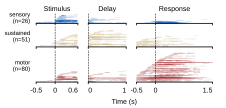

/hpc/home/ns458/coganlab/nanlinshi/tmp/ipykernel_633754/4056681870.py:142: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [8]:
agg = (
    subset.groupby(["channel", "time", "phase", "functional_cluster"], as_index=False)
    .agg(value=("value", "mean"), mask=("mask", "any"))
)
agg.loc[~agg["mask"], "value"] = np.nan

# Heatmap row order: sensory → sustain → motor
HEATMAP_CLUSTERS = ["sensory", "sustain", "motor"]

n_by_cluster = {
    c: int(subset.loc[subset.functional_cluster == c, "channel"].nunique())
    for c in HEATMAP_CLUSTERS
}
height_ratios = [max(n_by_cluster[c], 1) for c in HEATMAP_CLUSTERS]

# Crop to TRACE_PHASES; column widths match the traces.
def cluster_phase_channel_order_crop(
    agg: pd.DataFrame, phase: str, cluster: str
) -> list[str]:
    """Union channels for this cluster, sorted by first significant time in crop."""
    lo, hi = FIG2_TRACE_XLIMS[phase]
    phase_data = agg[
        (agg.phase == phase)
        & (agg.functional_cluster == cluster)
        & (agg.time >= lo)
        & (agg.time <= hi)
    ]
    channels = sorted(phase_data["channel"].unique())
    first_sig = []
    for ch in channels:
        ch_data = phase_data[phase_data.channel == ch]
        sig_times = ch_data.loc[ch_data["mask"], "time"].to_numpy()
        first_sig.append((ch, float(sig_times.min()) if len(sig_times) else np.inf))
    return [ch for ch, _ in sorted(first_sig, key=lambda x: x[1])]


width_ratios = [hi - lo for lo, hi in (FIG2_TRACE_XLIMS[p] for p in TRACE_PHASES)]

fig = plt.figure(
    figsize=(8 * cm, 0.02 * sum(height_ratios) * cm + 0.7 * cm),
)
gs = fig.add_gridspec(
    nrows=len(HEATMAP_CLUSTERS),
    ncols=len(TRACE_PHASES),
    height_ratios=height_ratios,
    width_ratios=width_ratios,
    hspace=0.15,
    wspace=FIG2_MARGINS["wspace"],
    left=FIG2_MARGINS["left"],
    right=FIG2_MARGINS["right"],
    bottom=0.24,
    top=0.88,
)
axes = np.empty((len(HEATMAP_CLUSTERS), len(TRACE_PHASES)), dtype=object)
for i in range(len(HEATMAP_CLUSTERS)):
    for j in range(len(TRACE_PHASES)):
        sharex = axes[0, j] if i > 0 else None
        axes[i, j] = fig.add_subplot(gs[i, j], sharex=sharex)

for i, cluster in enumerate(HEATMAP_CLUSTERS):
    cmap = CLUSTER_CMAPS[cluster]
    for j, phase in enumerate(TRACE_PHASES):
        ax = axes[i, j]
        lo, hi = FIG2_TRACE_XLIMS[phase]
        ordered = cluster_phase_channel_order_crop(agg, phase, cluster)
        phase_data = agg[
            (agg.phase == phase)
            & (agg.functional_cluster == cluster)
            & agg.channel.isin(ordered)
            & (agg.time >= lo)
            & (agg.time <= hi)
        ]

        if not ordered:
            ax.text(
                0.5, 0.5, "No channels",
                ha="center", va="center", transform=ax.transAxes, fontsize=fontsize,
            )
        else:
            pivot = (
                phase_data.pivot(index="channel", columns="time", values="value")
                .reindex(index=ordered)
            )
            da = xr.DataArray(
                pivot.to_numpy(dtype=float),
                coords={"channel": pivot.index, "time": pivot.columns.astype(float)},
                dims=["channel", "time"],
            )
            time_values = da.coords["time"].values.astype(float)
            step = np.diff(time_values).mean() if len(time_values) > 1 else 0.01
            time_edges = np.concatenate(
                (
                    [time_values[0] - step / 2],
                    time_values[:-1] + step / 2,
                    [time_values[-1] + step / 2],
                )
            )
            channel_edges = np.arange(len(ordered) + 1)
            T, C = np.meshgrid(time_edges, channel_edges)

            ax.pcolormesh(
                T, C, da.values, cmap=cmap, vmin=0, vmax=1,
                shading="auto", rasterized=True,
            )

        ax.axvline(x=0, color="k", linestyle="--", linewidth=0.5, clip_on=False)
        ax.set_xlim(lo, hi)
        ax.set_ylim(0, max(len(ordered), 1))
        ax.set_yticks([])
        ax.tick_params(axis="y", which="both", left=False, right=False, labelleft=False)
        sns.despine(ax=ax, offset=0, trim=False)
        ax.spines["left"].set_visible(False)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        ax.set_xticks(FIG2_TRACE_XTICKS[phase])
        ax.tick_params(
            axis="x",
            which="both",
            bottom=True,
            top=False,
            labelbottom=i == len(HEATMAP_CLUSTERS) - 1,
            length=2,
            width=0.75,
            labelsize=fontsize,
        )
        ax.spines["bottom"].set_visible(True)
        ax.set_xlabel("")

        if j == 0:
            ax.set_ylabel(
                f"{CLUSTER_LABELS[cluster]}\n(n={len(ordered)})",
                fontsize=6, rotation=0, ha="right", va="center", labelpad=6,
            )
        if i == 0:
            ax.set_title(phase.capitalize(), fontsize=fontsize, pad=2)

xmid = 0.5 * (FIG2_MARGINS["left"] + FIG2_MARGINS["right"])
fig.text(xmid, 0.025, "Time (s)", ha="center", va="bottom", fontsize=fontsize)

save_aligned_svg(fig, "fig2_hga_heatmap.svg")
plt.show()

plt.close("all")


## 5. Rank selection (justify *k*=3)

Reads the existing electrode-bootstrap metrics (`rank_selection_metrics.csv`).
Does **not** refit NMF. Primary rule in `chosen_k.json`: max cophenetic.
Dashed line marks canonical *k*=3.


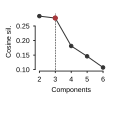

chosen k=3  rule=max_cophenetic  near-ties=[2, 3, 4]
Wrote /hpc/group/coganlab/nanlinshi/insula-functional/img/grant_nmf_30subjects/fig2/fig2_nmf_rank_k.svg


/hpc/home/ns458/coganlab/nanlinshi/tmp/ipykernel_633754/3211839526.py:23: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [9]:
import json

rank = pd.read_csv(NMF_DIR / "rank_selection_metrics.csv")
chosen = json.loads((NMF_DIR / "chosen_k.json").read_text(encoding="utf-8"))
k_nmf = int(chosen["k"])
ks = sorted(rank["k"].astype(int).tolist())
y_star = float(rank.loc[rank["k"].eq(k_nmf), "silhouette_cosine"].iloc[0])

fig, ax = plt.subplots(figsize=(4 * cm, 4 * cm))
fig.subplots_adjust(bottom=0.38, top=0.88, left=0.32, right=0.94)

ax.plot(rank["k"], rank["silhouette_cosine"], "o-", color="0.2", lw=1, markersize=3.5)
ax.scatter([k_nmf], [y_star], s=18, color="#A9373B", zorder=3)
ax.axvline(k_nmf, color="k", linestyle="--", linewidth=0.5)
ax.set_xlabel("Components", fontsize=fontsize)
ax.set_ylabel("Cosine sil.", fontsize=fontsize)
ax.set_xticks(ks)
ax.tick_params(labelsize=fontsize, width=0.75, length=2, which="both")
plt.setp(ax.spines.values(), linewidth=0.75)
sns.despine(ax=ax, offset=1, trim=True)

save_aligned_svg(fig, "fig2_nmf_rank_k.svg")
plt.show()
print(f"chosen k={k_nmf}  rule={chosen['rule']}  near-ties={chosen['near_tie_ks']}")
print("Wrote", IMG_DIR / "fig2_nmf_rank_k.svg")
plt.close("all")


## 6. Waveform PCA, k-means *k*=3

Same figure as `img/nmf/waveform_pca_kmeans.svg` (from `notebooks/nmf_pc_clustering.ipynb`).

Reads stored PC scores (`pc_scores.csv`). Fits k-means at NMF *k*=3 in the
embedding PCs, Hungarian-matches cluster names onto NMF labels, and plots
PC1–PC2 with marginal histograms. Does **not** refit NMF or overwrite
`channel_assignments.csv`.


ARI  NMF vs k-means k=3: 0.830


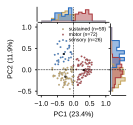

Wrote /hpc/group/coganlab/nanlinshi/insula-functional/img/grant_nmf_30subjects/fig2/fig2_waveform_pca_kmeans.svg


/hpc/home/ns458/coganlab/nanlinshi/tmp/ipykernel_633754/4031041259.py:116: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [10]:
import json

from matplotlib.ticker import MultipleLocator
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

scores = pd.read_csv(NMF_DIR / "pc_scores.csv")
meta = json.loads((NMF_DIR / "pc_clustering_meta.json").read_text(encoding="utf-8"))
n_embed = int(meta["n_embedding_pcs"])
k_nmf = 3
rng = int(meta["random_state"])
explained = np.asarray(meta["explained_variance_ratio"], dtype=float)

embed = scores[[f"PC{i}" for i in range(1, n_embed + 1)]].to_numpy(float)
nmf = scores["functional_cluster"].astype(str)
km3 = KMeans(n_clusters=k_nmf, n_init=50, random_state=rng).fit_predict(embed)
nmf_names = ordered_clusters(nmf)
conf = pd.crosstab(pd.Series(km3), nmf).reindex(columns=nmf_names, fill_value=0)
rows, cols = linear_sum_assignment(-conf.to_numpy(float))
km3_to_name = {int(conf.index[r]): nmf_names[c] for r, c in zip(rows, cols)}
km3_named = np.array([km3_to_name[int(v)] for v in km3])

print(f"ARI  NMF vs k-means k={k_nmf}: {adjusted_rand_score(nmf, km3):.3f}")

x = scores["PC1"].to_numpy(float)
y = scores["PC2"].to_numpy(float)
x_bins = np.linspace(np.floor(x.min() / 0.5) * 0.5, np.ceil(x.max() / 0.5) * 0.5, 20)
y_bins = np.linspace(np.floor(y.min() / 0.5) * 0.5, np.ceil(y.max() / 0.5) * 0.5, 20)

fig = plt.figure(figsize=(4 * cm, 4 * cm))
grid = fig.add_gridspec(
    2,
    2,
    width_ratios=(5.0, 1),
    height_ratios=(1, 5.0),
    wspace=0.06,
    hspace=0.06,
)
ax_histx = fig.add_subplot(grid[0, 0])
ax = fig.add_subplot(grid[1, 0], sharex=ax_histx)
ax_histy = fig.add_subplot(grid[1, 1], sharey=ax)

for cluster in nmf_names:
    mask = km3_named == cluster
    color = FUNCTION_COLORS.get(cluster, "0.4")
    ax.scatter(
        x[mask],
        y[mask],
        s=3,
        color=color,
        edgecolor="gray",
        linewidth=0.2,
        alpha=0.9,
        label=f"{CLUSTER_LABELS.get(cluster, cluster)} (n={int(mask.sum())})",
    )
    ax.scatter(
        x[mask].mean(),
        y[mask].mean(),
        s=3,
        marker="X",
        color=color,
        edgecolor="black",
        linewidth=0.5,
        zorder=3,
    )
    ax_histx.hist(
        x[mask],
        bins=x_bins,
        density=True,
        histtype="stepfilled",
        color=color,
        alpha=0.45,
        linewidth=0,
    )
    ax_histx.hist(x[mask], bins=x_bins, density=True, histtype="step", color=color, linewidth=1)
    ax_histy.hist(
        y[mask],
        bins=y_bins,
        density=True,
        histtype="stepfilled",
        orientation="horizontal",
        color=color,
        alpha=0.45,
        linewidth=0,
    )
    ax_histy.hist(
        y[mask],
        bins=y_bins,
        density=True,
        histtype="step",
        orientation="horizontal",
        color=color,
        linewidth=1,
    )

ax.set_xlabel(f"PC1 ({100 * explained[0]:.1f}%)", fontsize=fontsize)
ax.set_ylabel(f"PC2 ({100 * explained[1]:.1f}%)", fontsize=fontsize)
ax.axhline(0.0, color="k", linestyle="--", linewidth=0.5)
ax.axvline(0.0, color="k", linestyle="--", linewidth=0.5)
ax_histx.axvline(0.0, color="k", linestyle="--", linewidth=0.5)
ax_histy.axhline(0.0, color="k", linestyle="--", linewidth=0.5)
for axis in (ax, ax_histx, ax_histy):
    axis.tick_params(labelsize=fontsize, width=0.75, length=2, which="both")
    plt.setp(axis.spines.values(), linewidth=0.75)
    sns.despine(ax=axis, offset=1, trim=False)
ax.xaxis.set_major_locator(MultipleLocator(0.5))
ax.yaxis.set_major_locator(MultipleLocator(0.5))
ax_histx.tick_params(labelbottom=False, labelleft=False, left=False)
ax_histx.set_yticks([])
ax_histy.tick_params(labelleft=False, labelbottom=False, bottom=False)
ax_histy.set_xticks([])
ax.legend(frameon=False, fontsize=5, loc="upper right", handlelength=0.7, labelspacing=0.15, borderpad=0.1)

out = save_svg(fig, IMG_DIR / "fig2_waveform_pca_kmeans.svg")
plt.show()
print("Wrote", out)

plt.close("all")


## 6b. Dominance and mixed assignments

Stacked histogram of NMF **dominance** (`max(W) / sum(W)`) by hard label.
An electrode is **mixed** when winner minus runner-up loading proportion
is `< 0.20` (same cutoff as `functional_hga_specificity`). The dashed line
marks the equivalent two-way dominance (`0.60`). Mixed contacts stay in the
NMF hard-label results; they are only flagged here and on the spatial map.


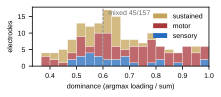

Wrote /hpc/group/coganlab/nanlinshi/insula-functional/img/grant_nmf_30subjects/fig2/fig2_nmf_dominance.svg
mixed (specificity_max < 0.2): 45 / 157 (29%)
functional_cluster
sustain    17
motor      18
sensory    10
Name: is_mixed, dtype: int64


/hpc/home/ns458/coganlab/nanlinshi/tmp/ipykernel_633754/562197890.py:50: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [11]:
from matplotlib.patches import Patch

assignments = annotate_mixed_assignments(assignments)
qc = assignments.loc[assignments["functional_cluster"].isin(CLUSTERS)].copy()
qc["cluster_label"] = qc["functional_cluster"].map(CLUSTER_LABELS)
n_mixed = int(qc["is_mixed"].sum())
n_all = len(qc)

fig, ax = plt.subplots(figsize=(8 * cm, 3 * cm))
sns.histplot(
    data=qc,
    x="dominance",
    hue="cluster_label",
    hue_order=HUE_ORDER,
    palette=PALETTE,
    multiple="stack",
    bins=20,
    binrange=(1 / 3, 1.0),
    ax=ax,
    legend=False,
    linewidth=0.3,
    edgecolor="white",
)
ax.axvline(MIXED_DOMINANCE_REF, color=MIXED_COLOR, lw=0.8, ls="--", zorder=3)
ax.set_xlim(1 / 3, 1.0)
ax.set_xlabel("dominance (argmax loading / sum)", **fontdict)
ax.set_ylabel("electrodes", **fontdict)
ax.tick_params(labelsize=fontsize)
ax.text(
    MIXED_DOMINANCE_REF + 0.02,
    0.95,
    f"mixed  {n_mixed}/{n_all}",
    transform=ax.get_xaxis_transform(),
    ha="left",
    va="top",
    fontsize=fontsize,
    color=MIXED_COLOR,
)
ax.legend(
    handles=[
        Patch(facecolor=FUNCTION_COLORS[c], edgecolor="none", label=CLUSTER_LABELS[c])
        for c in CLUSTERS
    ],
    frameon=False,
    fontsize=fontsize,
    loc="upper right",
)
fig.subplots_adjust(left=0.16, right=0.94, bottom=0.22, top=0.92)
out = save_svg(fig, IMG_DIR / "fig2_nmf_dominance.svg")
plt.show()
print("Wrote", out)
print(
    f"mixed (specificity_max < {MIXED_SPECIFICITY_MAX}): "
    f"{n_mixed} / {n_all} ({100 * n_mixed / n_all:.0f}%)"
)
print(qc.groupby("functional_cluster")["is_mixed"].sum().reindex(CLUSTERS).astype(int))

plt.close("all")


## 7. Insula spatial map (static)

Only the insula is drawn: whole-brain cortex is hidden (`alpha=0`), then the
insula faces from `aparc.a2009s` are added as a mesh in the same pale gray as
`functional_hga` (`(0.9, 0.9, 0.9)`, alpha `0.55`). Equal-size spheres colored
by NMF hard labels, plus KDE contour envelopes. Island contours around a single
electrode are dropped (`KDE_MIN_POINTS`); the point itself stays. Does **not**
encode HGA or split by phase. The screenshot is cropped to the insula; cluster
*n* is in the legend.

Renders in this notebook (no Slurm). Tune `KDE_BANDWIDTH_PX` / `KDE_LEVEL_FRAC`.


Using notebook 3d backend.


Reading labels from parcellation...


   read 75 labels from /cwork/ns458/ECoG_Recon/cvs_avg35_inMNI152/label/lh.aparc.a2009s.annot


   read 75 labels from /cwork/ns458/ECoG_Recon/cvs_avg35_inMNI152/label/rh.aparc.a2009s.annot


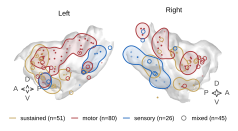

Wrote /hpc/group/coganlab/nanlinshi/insula-functional/img/grant_nmf_30subjects/fig2/fig2_insula_spatial_kdecontour.svg
functional_cluster
sustain    51
motor      80
sensory    26
mixed on map: 45 / 157 (specificity_max < 0.2)


/hpc/home/ns458/coganlab/nanlinshi/tmp/ipykernel_633754/3146265681.py:389: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [12]:
import os
import warnings

import mne
import pyvista as pv
from matplotlib.lines import Line2D
from matplotlib.path import Path as MplPath
from mne.viz import Brain
from scipy.ndimage import gaussian_filter
from scipy.spatial import cKDTree

os.environ.setdefault("PYVISTA_OFF_SCREEN", "true")
pv.OFF_SCREEN = True
mne.viz.set_3d_backend("notebook")

recon_dir = "/cwork/ns458/ECoG_Recon/"
template = "cvs_avg35_inMNI152"
insula_patterns = (
    "G_insular_short",
    "G_Ins_lg_and_S_cent_ins",
    "S_circular_insula_ant",
    "S_circular_insula_inf",
    "S_circular_insula_sup",
)
POINT_SIZE = 10.0
KDE_BANDWIDTH_PX = 25.0
KDE_LEVEL_FRAC = 0.18
KDE_FILL_ALPHA = 0.12
KDE_MIN_POINTS = 2
CROP_PAD_PX = 24
INSULA_COLOR = (0.9, 0.9, 0.9)
INSULA_LABEL_ALPHA = 0.55

labels = mne.read_labels_from_annot(
    subject=template,
    parc="aparc.a2009s",
    surf_name="pial",
    hemi="both",
    subjects_dir=recon_dir,
)
lh_pial_coords, lh_faces = mne.read_surface(f"{recon_dir}/{template}/surf/lh.pial")
rh_pial_coords, rh_faces = mne.read_surface(f"{recon_dir}/{template}/surf/rh.pial")
lh_tree = cKDTree(lh_pial_coords)
rh_tree = cKDTree(rh_pial_coords)


def _insula_vertices(hemi: str) -> np.ndarray:
    verts = []
    for lab in labels:
        if lab.hemi == hemi and any(p in lab.name for p in insula_patterns):
            verts.extend(lab.vertices)
    if not verts:
        raise RuntimeError(f"No insula labels for {hemi}")
    return np.unique(verts)


def _faces_to_polydata(coords, faces) -> pv.PolyData:
    faces_pv = np.hstack(
        [np.full((len(faces), 1), 3, dtype=np.int64), np.asarray(faces, dtype=np.int64)]
    ).ravel()
    return pv.PolyData(np.asarray(coords, dtype=float), faces_pv)


def insula_mesh(hemi: str, pial: np.ndarray, faces: np.ndarray):
    verts = _insula_vertices(hemi)
    keep = np.all(np.isin(faces, verts), axis=1)
    mesh = _faces_to_polydata(pial, faces[keep])
    center = pial[verts].mean(axis=0)
    return mesh, center


lh_insula, lh_insula_center = insula_mesh("lh", lh_pial_coords, lh_faces)
rh_insula, rh_insula_center = insula_mesh("rh", rh_pial_coords, rh_faces)


def snap_to_pial(coords, tree, pial):
    _, idx = tree.query(coords)
    return pial[idx]


def add_cluster_spheres(brain, coords, clusters, tree, pial, keep_mask=None):
    coords = np.asarray(coords, dtype=float)
    if coords.size == 0:
        return np.zeros((0, 3), dtype=float)
    snapped = snap_to_pial(coords, tree, pial)
    if keep_mask is None:
        keep_mask = np.ones(len(coords), dtype=bool)
    keep_mask = np.asarray(keep_mask, dtype=bool)
    for cluster in CLUSTERS:
        mask = (np.asarray(clusters) == cluster) & keep_mask
        if not mask.any():
            continue
        cloud = pv.PolyData(np.asarray(snapped[mask], dtype=float))
        brain._renderer.plotter.add_mesh(
            cloud,
            render_points_as_spheres=True,
            point_size=POINT_SIZE,
            color=FUNCTION_COLORS[cluster],
            lighting=False,
        )
    return snapped


def project_xy(plotter, points, image_shape):
    pts = np.asarray(points, dtype=float)
    if pts.size == 0:
        return np.zeros((0, 2), dtype=float)
    if hasattr(plotter, "project_points_to_pixels"):
        pix = np.asarray(plotter.project_points_to_pixels(pts), dtype=float)
        xy = np.asarray(pix[:, :2], dtype=float)
    else:
        import vtk

        renderer = plotter.renderer
        coordinate = vtk.vtkCoordinate()
        coordinate.SetCoordinateSystemToWorld()
        xy = np.zeros((len(pts), 2), dtype=float)
        for i, (x, y, z) in enumerate(pts):
            coordinate.SetValue(float(x), float(y), float(z))
            d = coordinate.GetComputedDisplayValue(renderer)
            xy[i] = (float(d[0]), float(d[1]))
    h = int(image_shape[0])
    xy[:, 1] = (h - 1) - xy[:, 1]
    return xy


def _keep_ring(ring, pts) -> bool:
    """Drop island contours that wrap fewer than KDE_MIN_POINTS electrodes."""
    if len(pts) < KDE_MIN_POINTS:
        return False
    return int(MplPath(np.asarray(ring, dtype=float)).contains_points(pts).sum()) >= KDE_MIN_POINTS


def kde_contour_rings(xy, image_shape, *, bandwidth_px=KDE_BANDWIDTH_PX, level_frac=KDE_LEVEL_FRAC):
    pts = np.asarray(xy, dtype=float)
    if len(pts) < 3:
        return []
    h, w = int(image_shape[0]), int(image_shape[1])
    dens = np.zeros((h, w), dtype=float)
    xs = np.clip(np.round(pts[:, 0]).astype(int), 0, w - 1)
    ys = np.clip(np.round(pts[:, 1]).astype(int), 0, h - 1)
    for x, y in zip(xs, ys):
        dens[y, x] += 1.0
    dens = gaussian_filter(dens, sigma=float(bandwidth_px))
    peak = float(dens.max())
    if peak <= 0:
        return []
    level = peak * float(level_frac)
    try:
        from skimage.measure import find_contours

        contours = find_contours(dens, level=level)
        rings = []
        for cont in contours:
            if len(cont) < 8:
                continue
            ring = np.column_stack([cont[:, 1], cont[:, 0]])
            ring = np.vstack([ring, ring[0]])
            if _keep_ring(ring, pts):
                rings.append(ring)
        return rings
    except ImportError:
        fig_c, ax_c = plt.subplots()
        yy, xx = np.mgrid[0:h, 0:w]
        cs = ax_c.contour(xx, yy, dens, levels=[level])
        rings = []
        for segs in cs.allsegs:
            for seg in segs:
                if len(seg) < 8:
                    continue
                ring = np.vstack([seg, seg[0]])
                if _keep_ring(ring, pts):
                    rings.append(ring)
        plt.close(fig_c)
        return rings


def draw_rings(ax, rings, color):
    for ring in rings:
        ax.fill(ring[:, 0], ring[:, 1], color=color, alpha=KDE_FILL_ALPHA, linewidth=0, zorder=3)
        ax.plot(
            ring[:, 0],
            ring[:, 1],
            color=color,
            linewidth=0.9,
            solid_capstyle="round",
            solid_joinstyle="round",
            zorder=4,
        )


def draw_ap_dv(ax, *, anterior_is_left: bool, corner: str):
    """A–P / D–V orientation cross in axes-fraction coordinates."""
    if corner == "lower left":
        x0, y0, arm = 0.16, 0.18, 0.08
    else:
        # Further into the outer white corner so P does not meet the mesh.
        x0, y0, arm = 0.91, 0.16, 0.07
    gap = 0.012
    if anterior_is_left:
        tips = {"A": (x0 - arm, y0), "P": (x0 + arm, y0), "D": (x0, y0 + arm), "V": (x0, y0 - arm)}
    else:
        tips = {"A": (x0 + arm, y0), "P": (x0 - arm, y0), "D": (x0, y0 + arm), "V": (x0, y0 - arm)}
    for label, (tx, ty) in tips.items():
        sx = x0 + gap * np.sign(tx - x0) if tx != x0 else x0
        sy = y0 + gap * np.sign(ty - y0) if ty != y0 else y0
        ax.annotate(
            "",
            xy=(tx, ty),
            xytext=(sx, sy),
            xycoords="axes fraction",
            textcoords="axes fraction",
            arrowprops=dict(arrowstyle="->", color="0.25", lw=0.7, mutation_scale=7),
            annotation_clip=False,
        )
        px = 0.03 * np.sign(tx - x0) if tx != x0 else 0.0
        py = 0.035 * np.sign(ty - y0) if ty != y0 else 0.0
        ax.text(
            tx + px,
            ty + py,
            label,
            transform=ax.transAxes,
            ha="center",
            va="center",
            fontsize=fontsize,
            color="0.25",
            clip_on=False,
        )


def crop_to_content(img, xy, pad=CROP_PAD_PX):
    rgb = np.asarray(img)
    mask = np.any(rgb < 250, axis=2)
    if not mask.any():
        return rgb, np.asarray(xy, dtype=float)
    ys, xs = np.nonzero(mask)
    y0 = max(0, int(ys.min()) - pad)
    y1 = min(rgb.shape[0], int(ys.max()) + 1 + pad)
    x0 = max(0, int(xs.min()) - pad)
    x1 = min(rgb.shape[1], int(xs.max()) + 1 + pad)
    xy_c = np.asarray(xy, dtype=float).copy()
    if xy_c.size:
        xy_c[:, 0] -= x0
        xy_c[:, 1] -= y0
    return rgb[y0:y1, x0:x1], xy_c


def render_hemi(hemi: str, coords, clusters, sphere_mask=None):
    brain = Brain(
        template,
        subjects_dir=recon_dir,
        surf="pial",
        hemi=hemi,
        background="white",
        show=False,
        cortex=INSULA_COLOR,
        alpha=0.0,
        size=(800, 800),
    )
    plotter = brain._renderer.plotter
    mesh = lh_insula if hemi == "lh" else rh_insula
    plotter.add_mesh(
        mesh,
        color=INSULA_COLOR,
        opacity=INSULA_LABEL_ALPHA,
        lighting=True,
        smooth_shading=True,
    )
    tree = lh_tree if hemi == "lh" else rh_tree
    pial = lh_pial_coords if hemi == "lh" else rh_pial_coords
    snapped = add_cluster_spheres(
        brain, coords, clusters, tree, pial, keep_mask=sphere_mask
    )
    center = lh_insula_center if hemi == "lh" else rh_insula_center
    az = 180 if hemi == "lh" else 0
    brain.show_view(azimuth=az, elevation=90, distance=180, focalpoint=center)
    for _ in range(3):
        plotter.render()
    img = np.asarray(brain.screenshot(mode="rgb"))
    xy = project_xy(plotter, snapped, img.shape[:2])
    brain.close()
    return img, xy


if "is_mixed" not in assignments.columns:
    assignments = annotate_mixed_assignments(assignments)

spatial = assignments.loc[
    assignments["functional_cluster"].isin(CLUSTERS)
    & ~assignments["subject"].isin(EXCLUDE_SUBJECTS)
    & assignments[["x", "y", "z"]].notna().all(axis=1)
].copy()
cord = spatial[["x", "y", "z"]].to_numpy(float)
clust = spatial["functional_cluster"].to_numpy()
mixed = spatial["is_mixed"].to_numpy(dtype=bool)
mask_lh = cord[:, 0] < 0
mask_rh = cord[:, 0] > 0

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    lh_img, lh_xy = render_hemi(
        "lh", cord[mask_lh], clust[mask_lh], sphere_mask=~mixed[mask_lh]
    )
    rh_img, rh_xy = render_hemi(
        "rh", cord[mask_rh], clust[mask_rh], sphere_mask=~mixed[mask_rh]
    )

lh_img, lh_xy = crop_to_content(lh_img, lh_xy)
rh_img, rh_xy = crop_to_content(rh_img, rh_xy)
bw_px = KDE_BANDWIDTH_PX  # crop after render; keep the 800-px KDE scale

fig, axes = plt.subplots(1, 2, figsize=(8 * cm , 3.5 * cm))
for ax, img, xy, clusters_hemi, mixed_hemi, title in (
    (axes[0], lh_img, lh_xy, clust[mask_lh], mixed[mask_lh], "Left"),
    (axes[1], rh_img, rh_xy, clust[mask_rh], mixed[mask_rh], "Right"),
):
    ax.imshow(img)
    ax.set_xlim(0, img.shape[1])
    ax.set_ylim(img.shape[0], 0)
    ax.axis("off")
    ax.set_title(title, fontsize=fontsize)
    in_frame = (
        (xy[:, 0] >= 0)
        & (xy[:, 0] < img.shape[1])
        & (xy[:, 1] >= 0)
        & (xy[:, 1] < img.shape[0])
    )
    mixed_hemi = np.asarray(mixed_hemi, dtype=bool)
    for cluster in CLUSTERS:
        pts = xy[
            in_frame
            & (np.asarray(clusters_hemi) == cluster)
            & ~mixed_hemi
        ]
        draw_rings(
            ax,
            kde_contour_rings(pts, img.shape[:2], bandwidth_px=bw_px),
            FUNCTION_COLORS[cluster],
        )
    mixed_pts = xy[in_frame & mixed_hemi]
    mixed_clust = np.asarray(clusters_hemi)[in_frame & mixed_hemi]
    if len(mixed_pts):
        ax.scatter(
            mixed_pts[:, 0],
            mixed_pts[:, 1],
            s=14,
            facecolors="none",
            edgecolors=[FUNCTION_COLORS[c] for c in mixed_clust],
            linewidths=0.7,
            zorder=5,
        )
    if title == "Left":
        draw_ap_dv(ax, anterior_is_left=True, corner="lower left")
    else:
        draw_ap_dv(ax, anterior_is_left=False, corner="lower right")

n_by_cluster = spatial.groupby("functional_cluster")["channel"].nunique()
n_mixed_map = int(spatial["is_mixed"].sum())
fig.legend(
    handles=[
        Line2D(
            [0],
            [0],
            color=FUNCTION_COLORS[c],
            linewidth=0.9,
            label=f"{CLUSTER_LABELS[c]}  (n={int(n_by_cluster.get(c, 0))})",
        )
        for c in CLUSTERS
    ]
    + [
        Line2D(
            [0],
            [0],
            marker="o",
            color="none",
            markerfacecolor="none",
            markeredgecolor=MIXED_COLOR,
            markeredgewidth=0.7,
            markersize=4.5,
            label=f"mixed  (n={n_mixed_map})",
        )
    ],
    frameon=False,
    fontsize=6,
    loc="upper center", ncol=4, bbox_to_anchor=(.5,-.01), handlelength=1, columnspacing=.8,
)
fig.subplots_adjust(wspace=0.02, left=0.02, right=0.98, top=0.92, bottom=0.02)
out = save_svg(fig, IMG_DIR / "fig2_insula_spatial_kdecontour.svg")
plt.show()
print("Wrote", out)
print(n_by_cluster.reindex(CLUSTERS).to_string())
print(
    f"mixed on map: {n_mixed_map} / {len(spatial)} "
    f"(specificity_max < {MIXED_SPECIFICITY_MAX})"
)

plt.close("all")


### NMF spatial weights — separate Gaussian maps

These maps preserve the continuous `loading_sensory`, `loading_sustain`, and `loading_motor` values from the Figure 2 assignments table. Each loading is rendered separately; no winner-take-all cluster labels or RGB blending are used. The dark 2D envelope follows the same thresholded visible support and keeps one dominant smooth loop per component × hemisphere.

In [13]:
import matplotlib.colors as mcolors
from matplotlib.backends.backend_agg import FigureCanvasAgg
from matplotlib.figure import Figure
from matplotlib.patches import Patch
from scipy import ndimage
from scipy.spatial.distance import cdist

# Gaussian density and display parameters ported from notebooks/nmf_weight_density.ipynb.
DENSITY_BANDWIDTH = 5.0       # mm; Gaussian kernel sigma
DENSITY_MAX_DISTANCE = 6.0    # mm; zero density beyond nearest electrode
DENSITY_VISIBLE_FRACTION = 0.40  # retain each component × hemisphere density core
DENSITY_COLOR_VMAX_PERCENTILE = 99.0
WEIGHT_DENSITY_COMPONENTS = ("sensory", "sustain", "motor")
WEIGHT_DENSITY_LOADING_COLS = {
    name: f"loading_{name}" for name in WEIGHT_DENSITY_COMPONENTS
}

# The envelope is extracted from the already-thresholded rendered overlay.
WEIGHT_DENSITY_ENVELOPE_MIN_COLOR_SIGNAL = 0.03
WEIGHT_DENSITY_ENVELOPE_CLOSE_RADIUS_PX = 18
WEIGHT_DENSITY_ENVELOPE_MIN_AREA_PX = 120
WEIGHT_DENSITY_ENVELOPE_SMOOTH_SIGMA_PX = 7.0
WEIGHT_DENSITY_ENVELOPE_LINE_WIDTH_PX = 1.4
WEIGHT_DENSITY_ENVELOPE_COLOR = "#222222"

weight_density_required = [
    "channel", "subject", "hemi", "x", "y", "z",
    *WEIGHT_DENSITY_LOADING_COLS.values(),
]
if not NMF_ASSIGNMENTS.is_file():
    raise FileNotFoundError(
        f"Missing NMF assignments: {NMF_ASSIGNMENTS}\n"
        "Expected results/nmf/channel_assignments.csv with loading_* columns."
    )

weight_density_assignments = pd.read_csv(NMF_ASSIGNMENTS)
weight_density_missing = [
    col for col in weight_density_required
    if col not in weight_density_assignments.columns
]
if weight_density_missing:
    raise KeyError(
        f"assignments missing columns {weight_density_missing}. "
        f"Present: {list(weight_density_assignments.columns)}"
    )

# Coordinates and loadings come directly from the same Figure 2 assignments table.
weight_density_frame = weight_density_assignments.loc[
    ~weight_density_assignments["subject"].astype(str).isin(EXCLUDE_SUBJECTS)
    & weight_density_assignments[["x", "y", "z"]].notna().all(axis=1)
].copy()
for col in WEIGHT_DENSITY_LOADING_COLS.values():
    weight_density_frame[col] = np.clip(
        pd.to_numeric(weight_density_frame[col], errors="coerce").fillna(0.0),
        0.0,
        None,
    )

print(f"NMF weight-density electrodes: {len(weight_density_frame)}")
print(weight_density_frame[list(WEIGHT_DENSITY_LOADING_COLS.values())].describe().round(3))
plt.close("all")


NMF weight-density electrodes: 157
       loading_sensory  loading_sustain  loading_motor
count          157.000          157.000        157.000
mean             0.227            0.330          0.468
std              0.237            0.256          0.293
min              0.000            0.000          0.000
25%              0.034            0.096          0.215
50%              0.135            0.291          0.466
75%              0.330            0.564          0.730
max              0.911            0.860          0.954


In [14]:
def weight_density_make_insula_brain(hemi: str):
    """Hide the whole cortex; the insula is added as one standalone mesh below."""
    return Brain(
        template,
        subjects_dir=recon_dir,
        surf="pial",
        hemi=hemi,
        background="white",
        show=False,
        cortex=INSULA_COLOR,
        alpha=0.0,
        size=(800, 800),
    )


def weight_density_compute(
    surface_coords: np.ndarray,
    electrode_coords: np.ndarray,
    electrode_weights: np.ndarray,
    *,
    bandwidth: float = DENSITY_BANDWIDTH,
    max_distance: float = DENSITY_MAX_DISTANCE,
) -> np.ndarray:
    """Gaussian pial-surface density for one continuous NMF loading."""
    density = np.zeros(len(surface_coords), dtype=float)
    if len(electrode_coords) == 0:
        return density
    weights = np.clip(np.asarray(electrode_weights, dtype=float), 0.0, None)
    distances = cdist(surface_coords, electrode_coords)
    near = distances.min(axis=1) < max_distance
    if near.any():
        kernel = np.exp(-distances[near] ** 2 / (2.0 * bandwidth ** 2))
        density[near] = kernel @ weights
    return density


def weight_density_to_rgba(
    density: np.ndarray,
    color_rgb: np.ndarray,
    *,
    visible_fraction: float = DENSITY_VISIBLE_FRACTION,
    vmax_percentile: float = DENSITY_COLOR_VMAX_PERCENTILE,
) -> np.ndarray:
    """Per-vertex RGBA for one insula mesh.

    Below threshold, vertices retain the translucent gray insula style. Above
    threshold, RGB is the pure component color and alpha follows a full-range
    smoothstep from the threshold to the robust density maximum.
    """
    if not 0.0 <= visible_fraction < 1.0:
        raise ValueError("visible_fraction must be in [0, 1)")
    if not 0.0 < vmax_percentile <= 100.0:
        raise ValueError("vmax_percentile must be in (0, 100]")
    density = np.nan_to_num(
        np.asarray(density, dtype=float), nan=0.0, posinf=0.0, neginf=0.0
    )
    n = len(density)
    rgba = np.empty((n, 4), dtype=float)
    rgba[:, :3] = np.asarray(INSULA_COLOR, dtype=float)
    rgba[:, 3] = float(INSULA_LABEL_ALPHA)
    positive = density > 0
    if positive.any():
        peak = float(np.max(density[positive]))
        threshold = visible_fraction * peak
        vmax = float(np.percentile(density[positive], vmax_percentile))
        vmax = max(vmax, threshold + np.finfo(float).eps * max(peak, 1.0))
        scaled = np.clip((density - threshold) / (vmax - threshold), 0.0, 1.0)
        alpha = scaled * scaled * (3.0 - 2.0 * scaled)
        visible = density >= threshold
        rgba[visible, :3] = np.asarray(color_rgb, dtype=float)
        rgba[visible, 3] = alpha[visible]
    return rgba


def weight_density_add_insula_mesh(brain, hemi: str, vertex_rgba: np.ndarray) -> None:
    """Add one lit insula mesh with per-vertex density RGBA."""
    mesh = (lh_insula if hemi == "lh" else rh_insula).copy(deep=True)
    mesh["rgba"] = (np.clip(vertex_rgba, 0.0, 1.0) * 255.0).astype(np.uint8)
    brain._renderer.plotter.add_mesh(
        mesh,
        scalars="rgba",
        rgba=True,
        lighting=True,
        smooth_shading=True,
    )


def weight_density_color_signal(img: np.ndarray, color_rgb: np.ndarray) -> np.ndarray:
    """Estimate overlay alpha from chroma while rejecting white/gray cortex."""
    pixels = np.asarray(img)
    rgb = pixels[:, :, :3].astype(float) / 255.0
    target = np.asarray(color_rgb, dtype=float)
    target_chroma = target - target.mean()
    denom = float(np.dot(target_chroma, target_chroma))
    if denom <= 1e-12:
        return np.zeros(rgb.shape[:2], dtype=float)
    pixel_chroma = rgb - rgb.mean(axis=2, keepdims=True)
    signal = np.tensordot(pixel_chroma, target_chroma, axes=([2], [0])) / denom
    if pixels.shape[2] == 4:
        signal *= pixels[:, :, 3].astype(float) / 255.0
    return np.clip(signal, 0.0, 1.0)


def weight_density_disk(radius: int) -> np.ndarray:
    radius = max(0, int(radius))
    yy, xx = np.ogrid[-radius : radius + 1, -radius : radius + 1]
    return (xx * xx + yy * yy) <= radius * radius


def weight_density_dominant_mask(signal: np.ndarray) -> np.ndarray | None:
    peak = float(np.max(signal)) if signal.size else 0.0
    if peak < WEIGHT_DENSITY_ENVELOPE_MIN_COLOR_SIGNAL:
        return None
    # Gray below-threshold vertices have negligible component chroma.
    mask = signal >= WEIGHT_DENSITY_ENVELOPE_MIN_COLOR_SIGNAL
    mask = ndimage.binary_closing(
        mask,
        structure=weight_density_disk(WEIGHT_DENSITY_ENVELOPE_CLOSE_RADIUS_PX),
    )
    mask = ndimage.binary_fill_holes(mask)
    labels_2d, count = ndimage.label(mask)
    if count == 0:
        return None
    areas = np.bincount(labels_2d.ravel(), minlength=count + 1)
    masses = np.bincount(
        labels_2d.ravel(), weights=signal.ravel(), minlength=count + 1
    )
    valid = np.flatnonzero(areas >= WEIGHT_DENSITY_ENVELOPE_MIN_AREA_PX)
    valid = valid[valid != 0]
    if len(valid) == 0:
        return None
    main_label = int(valid[np.argmax(masses[valid])])
    return ndimage.binary_fill_holes(labels_2d == main_label)


def weight_density_smooth_envelope(mask: np.ndarray) -> np.ndarray | None:
    smooth = ndimage.gaussian_filter(
        np.pad(mask.astype(float), 1),
        sigma=WEIGHT_DENSITY_ENVELOPE_SMOOTH_SIGMA_PX,
    )
    tmp_fig = Figure()
    tmp_ax = tmp_fig.subplots()
    contour_set = tmp_ax.contour(smooth, levels=[0.5])
    paths = [segment - 1.0 for segment in contour_set.allsegs[0] if len(segment) >= 4]
    if not paths:
        return None

    def polygon_area(points: np.ndarray) -> float:
        x, y = points[:, 0], points[:, 1]
        return 0.5 * abs(np.dot(x, np.roll(y, 1)) - np.dot(y, np.roll(x, 1)))

    return max(paths, key=polygon_area)


def weight_density_add_envelope(img: np.ndarray, color_rgb: np.ndarray) -> np.ndarray:
    signal = weight_density_color_signal(img, color_rgb)
    mask = weight_density_dominant_mask(signal)
    if mask is None:
        return np.asarray(img)
    envelope = weight_density_smooth_envelope(mask)
    if envelope is None:
        return np.asarray(img)

    rgb = np.asarray(img)[:, :, :3]
    height, width = rgb.shape[:2]
    dpi = 100
    fig = Figure(figsize=(width / dpi, height / dpi), dpi=dpi, facecolor="white")
    canvas = FigureCanvasAgg(fig)
    ax = fig.add_axes([0, 0, 1, 1], facecolor="white")
    ax.imshow(rgb, interpolation="nearest")
    ax.plot(
        envelope[:, 0],
        envelope[:, 1],
        color=WEIGHT_DENSITY_ENVELOPE_COLOR,
        linewidth=WEIGHT_DENSITY_ENVELOPE_LINE_WIDTH_PX * 72.0 / dpi,
        solid_capstyle="round",
        solid_joinstyle="round",
    )
    ax.set_xlim(-0.5, width - 0.5)
    ax.set_ylim(height - 0.5, -0.5)
    ax.axis("off")
    canvas.draw()
    return np.asarray(canvas.buffer_rgba())[:, :, :3].copy()


def weight_density_crop(img: np.ndarray, pad: int = CROP_PAD_PX) -> np.ndarray:
    """Crop the RGB brain plus envelope together, preserving their alignment."""
    cropped, _ = crop_to_content(
        np.asarray(img)[:, :, :3], np.empty((0, 2), dtype=float), pad=pad
    )
    return cropped


def weight_density_render_hemi(
    hemi: str,
    coords: np.ndarray,
    weights: np.ndarray,
    color_hex: str,
) -> np.ndarray:
    brain = weight_density_make_insula_brain(hemi)
    insula = lh_insula if hemi == "lh" else rh_insula
    density = weight_density_compute(np.asarray(insula.points), coords, weights)
    color_rgb = np.asarray(mcolors.to_rgb(color_hex))
    vertex_rgba = weight_density_to_rgba(density, color_rgb)
    weight_density_add_insula_mesh(brain, hemi, vertex_rgba)
    center = lh_insula_center if hemi == "lh" else rh_insula_center
    brain.show_view(
        azimuth=180 if hemi == "lh" else 0,
        elevation=90,
        distance=180,
        focalpoint=center,
    )
    for _ in range(3):
        brain._renderer.plotter.render()
    img = np.asarray(brain.screenshot(mode="rgb"))
    brain.close()
    img = weight_density_add_envelope(img, color_rgb)
    return weight_density_crop(img)
plt.close("all")


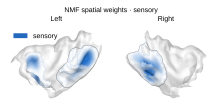

Wrote /hpc/group/coganlab/nanlinshi/insula-functional/img/grant_nmf_30subjects/fig2/fig2_nmf_weight_density_sensory.svg


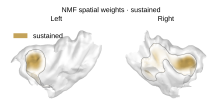

Wrote /hpc/group/coganlab/nanlinshi/insula-functional/img/grant_nmf_30subjects/fig2/fig2_nmf_weight_density_sustain.svg


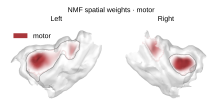

Wrote /hpc/group/coganlab/nanlinshi/insula-functional/img/grant_nmf_30subjects/fig2/fig2_nmf_weight_density_motor.svg


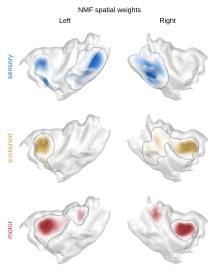

Wrote /hpc/group/coganlab/nanlinshi/insula-functional/img/grant_nmf_30subjects/fig2/fig2_nmf_weight_density_all.svg


/hpc/home/ns458/coganlab/nanlinshi/tmp/ipykernel_633754/2857488849.py:90: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [15]:
weight_density_coords = weight_density_frame[["x", "y", "z"]].to_numpy(float)
weight_density_mask_lh = weight_density_coords[:, 0] < 0
weight_density_mask_rh = weight_density_coords[:, 0] > 0
weight_density_images = {}

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for name in WEIGHT_DENSITY_COMPONENTS:
        weights = weight_density_frame[WEIGHT_DENSITY_LOADING_COLS[name]].to_numpy(float)
        color = FUNCTION_COLORS[name]
        lh_img = weight_density_render_hemi(
            "lh",
            weight_density_coords[weight_density_mask_lh],
            weights[weight_density_mask_lh],
            color,
        )
        rh_img = weight_density_render_hemi(
            "rh",
            weight_density_coords[weight_density_mask_rh],
            weights[weight_density_mask_rh],
            color,
        )
        weight_density_images[name] = (lh_img, rh_img)

        fig, axes = plt.subplots(1, 2, figsize=(8 * cm, 3.5 * cm))
        axes[0].imshow(lh_img)
        axes[0].axis("off")
        axes[0].set_title("Left", fontsize=fontsize)
        axes[1].imshow(rh_img)
        axes[1].axis("off")
        axes[1].set_title("Right", fontsize=fontsize)
        axes[0].legend(
            handles=[Patch(facecolor=color, label=CLUSTER_LABELS.get(name, name))],
            loc="upper left",
            fontsize=fontsize,
            frameon=False,
        )
        fig.suptitle(
            f"NMF spatial weights · {CLUSTER_LABELS.get(name, name)}",
            fontsize=fontsize,
        )
        fig.subplots_adjust(
            wspace=0.02, left=0.02, right=0.98, top=0.78, bottom=0.02
        )
        out = save_svg(fig, IMG_DIR / f"fig2_nmf_weight_density_{name}.svg")
        plt.show()
        print("Wrote", out)

fig, axes = plt.subplots(
    len(WEIGHT_DENSITY_COMPONENTS),
    2,
    figsize=(8 * cm, 3.2 * cm * len(WEIGHT_DENSITY_COMPONENTS)),
)
for row, name in enumerate(WEIGHT_DENSITY_COMPONENTS):
    lh_img, rh_img = weight_density_images[name]
    axes[row, 0].imshow(lh_img)
    axes[row, 0].axis("off")
    axes[row, 1].imshow(rh_img)
    axes[row, 1].axis("off")
    if row == 0:
        axes[row, 0].set_title("Left", fontsize=fontsize)
        axes[row, 1].set_title("Right", fontsize=fontsize)
    axes[row, 0].text(
        -0.02,
        0.5,
        CLUSTER_LABELS.get(name, name),
        transform=axes[row, 0].transAxes,
        va="center",
        ha="right",
        fontsize=fontsize,
        color=FUNCTION_COLORS[name],
        rotation=90,
    )

fig.suptitle(
    "NMF spatial weights",
    fontsize=fontsize,
)
fig.subplots_adjust(
    wspace=0.02,
    hspace=0.08,
    left=0.08,
    right=0.98,
    top=0.90,
    bottom=0.02,
)
weight_density_out_all = save_svg(
    fig, IMG_DIR / "fig2_nmf_weight_density_all.svg"
)
plt.show()
print("Wrote", weight_density_out_all)
plt.close("all")


## 8. Cluster × Hammers pies

One pie per cluster: **ant. short** (ASG), **int. short** (pole + MSG + PSG),
**long gyri** (ALG + PLG). Hammers labels from packaged HGA, not Destrieux.
Pies only — add leader lines in Illustrator if needed.


Hammers-labeled channels: 156 / 157 (assigned n=157)
group               ASG  intermediate  long
functional_cluster                         
sustain              22            19     9
motor                19            33    28
sensory               0             4    22
n pie / n assigned
                    pie  assigned
functional_cluster               
sustain              50        51
motor                80        80
sensory              26        26


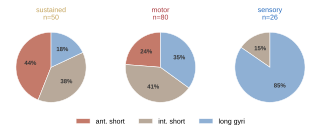

Wrote /hpc/group/coganlab/nanlinshi/insula-functional/img/grant_nmf_30subjects/fig2/fig2_insula_cluster_parcel_pies.svg


/hpc/home/ns458/coganlab/nanlinshi/tmp/ipykernel_633754/2018338752.py:146: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [16]:
from matplotlib.patches import Patch

from src.connectivity.pairwise.seeds import hammers_insula_subregion

GROUP_ORDER = ["ASG", "intermediate", "long"]
GROUP_LABELS = {
    "ASG": "ant. short",
    "intermediate": "int. short",
    "long": "long gyri",
}
GROUP_COLORS = {
    "ASG": "#C47A6A",
    "intermediate": "#B8A99A",
    "long": "#8FB0D4",
}
SUBREGION_TO_GROUP = {
    "ASG": "ASG",
    "AP": "intermediate",
    "MSG": "intermediate",
    "PSG": "intermediate",
    "ALG": "long",
    "PLG": "long",
}


def _label_mode(series):
    modes = series.mode()
    return modes.iloc[0] if len(modes) else series.iloc[0]


def hammers_label_by_channel(channels):
    """Hammers gyrus labels for NMF channels. Prefer in-memory subset, else one HGA file per subject."""
    wanted = set(channels)
    src = None
    if "subset" in globals() and isinstance(subset, pd.DataFrame) and "label" in subset.columns:
        src = subset.loc[subset["channel"].isin(wanted), ["channel", "label"]].dropna()
        src = src[~src["label"].astype(str).isin(["0", "nan", ""])]
    if src is None or src["channel"].nunique() < 0.5 * len(wanted):
        wanted_subjects = {str(ch).split("_", 1)[0] for ch in wanted}
        found = {}
        hga_root = hga_results_dir(TASKS[0]).parent
        for sub in sorted(wanted_subjects):
            matches = sorted(hga_root.glob(f"*/sub-{sub}/HGA/*_time.csv"))
            if matches:
                found[sub] = matches[0]
        frames = []
        for path in found.values():
            df = pd.read_csv(path, usecols=["channel", "label"])
            df = df[df["channel"].isin(wanted)]
            frames.append(df)
        src = (
            pd.concat(frames, ignore_index=True)
            if frames
            else pd.DataFrame(columns=["channel", "label"])
        )
        src = src.dropna(subset=["channel", "label"])
        src = src[~src["label"].astype(str).isin(["0", "nan", ""])]
    if src.empty:
        raise RuntimeError("No Hammers labels found for assigned channels.")
    return src.groupby("channel")["label"].agg(_label_mode)


parcel_df = assignments.loc[
    assignments["functional_cluster"].isin(CLUSTERS)
    & ~assignments["subject"].isin(EXCLUDE_SUBJECTS),
    ["channel", "functional_cluster"],
].drop_duplicates("channel").copy()
parcel_df["label"] = parcel_df["channel"].map(hammers_label_by_channel(parcel_df["channel"]))
parcel_df["subregion"] = parcel_df["label"].map(hammers_insula_subregion)
parcel_df["group"] = parcel_df["subregion"].map(SUBREGION_TO_GROUP)
parcel_ok = parcel_df.dropna(subset=["group"]).copy()

ct = (
    parcel_ok.groupby(["functional_cluster", "group"])
    .size()
    .unstack(fill_value=0)
    .reindex(index=CLUSTERS, columns=GROUP_ORDER, fill_value=0)
    .astype(int)
)
n_labeled = parcel_ok.groupby("functional_cluster")["channel"].nunique()
n_assigned = parcel_df.groupby("functional_cluster")["channel"].nunique()
print(
    f"Hammers-labeled channels: {len(parcel_ok)} / {len(parcel_df)} "
    f"(assigned n={int(n_assigned.sum())})"
)
print(ct.to_string())
print("n pie / n assigned")
print(
    pd.DataFrame({"pie": n_labeled, "assigned": n_assigned})
    .reindex(CLUSTERS)
    .fillna(0)
    .astype(int)
    .to_string()
)


def _style_pie_autotexts(autotexts):
    for text in autotexts:
        text.set_color("0.2")
        text.set_fontweight("bold")
        text.set_fontsize(6)


fig, axes = plt.subplots(1, len(CLUSTERS), figsize=(FIG2_WIDTH, 4.2 * cm))
for ax, cluster in zip(axes, CLUSTERS):
    sizes = np.asarray([int(ct.loc[cluster, g]) for g in GROUP_ORDER], dtype=int)
    keep = sizes > 0
    if not keep.any():
        ax.axis("off")
        continue
    _, _, autotexts = ax.pie(
        sizes[keep],
        labels=None,
        colors=[GROUP_COLORS[g] for g, on in zip(GROUP_ORDER, keep) if on],
        autopct=lambda pct: f"{pct:.0f}%" if pct >= 8 else "",
        startangle=90,
        textprops={"fontsize": fontsize},
        wedgeprops={"linewidth": 0.5, "edgecolor": "white"},
    )
    _style_pie_autotexts(autotexts)
    ax.set_title(
        f"{CLUSTER_LABELS[cluster]}\nn={int(sizes.sum())}",
        fontsize=fontsize,
        color=FUNCTION_COLORS[cluster],
        pad=4,
    )

fig.legend(
    handles=[
        Patch(
            facecolor=GROUP_COLORS[g],
            edgecolor="white",
            linewidth=0.5,
            label=GROUP_LABELS[g],
        )
        for g in GROUP_ORDER
    ],
    frameon=False,
    fontsize=fontsize,
    loc="lower center",
    ncol=len(GROUP_ORDER),
    bbox_to_anchor=(0.5, -0.08),
)
fig.tight_layout()
out = save_svg(fig, IMG_DIR / "fig2_insula_cluster_parcel_pies.svg")
plt.show()
print("Wrote", out)

plt.close("all")


## 8b. Six Hammers gyri pies (comparison)

Same electrodes as cell 8, but one wedge per gyrus, anterior → posterior:
AP, ASG, MSG, PSG, ALG, PLG. Cluster gold/red/blue stay on the titles.

Anatomical fill: set `GYRUS_PALETTE` to `purples` (default), `teal`, or `split`
(short gyri teal, long gyri plum).


subregion           AP  ASG  MSG  PSG  ALG  PLG
functional_cluster                             
sustain             14   22    1    4    2    7
motor                9   19   12   12   22    6
sensory              3    0    0    1    5   17
n by cluster: {'sustain': 50, 'motor': 80, 'sensory': 26}


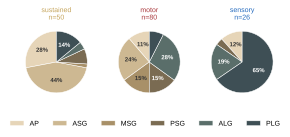

Wrote /hpc/group/coganlab/nanlinshi/insula-functional/img/grant_nmf_30subjects/fig2/fig2_insula_cluster_parcel_pies_k6.svg


/hpc/home/ns458/coganlab/nanlinshi/tmp/ipykernel_633754/4167831737.py:100: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [17]:
from matplotlib.patches import Patch

from src.connectivity.pairwise.seeds import hammers_insula_subregion

GYRUS_ORDER = ["AP", "ASG", "MSG", "PSG", "ALG", "PLG"]
GYRUS_LABELS = {g: g for g in GYRUS_ORDER}
# Anterior (sand) → posterior (slate). Avoid cluster gold / red / blue.
GYRUS_COLORS = {
    "AP": "#E6D5B8",
    "ASG": "#CDB892",
    "MSG": "#A89068",
    "PSG": "#7A6B52",
    "ALG": "#5A6E6A",
    "PLG": "#3E4F55",
}


def _hex_luminance(hex_color: str) -> float:
    h = hex_color.lstrip("#")
    r, g, b = (int(h[i : i + 2], 16) / 255 for i in (0, 2, 4))
    return 0.2126 * r + 0.7152 * g + 0.0722 * b


if "parcel_ok" in globals() and "subregion" in parcel_ok.columns:
    parcel_k6 = parcel_ok.dropna(subset=["subregion"]).copy()
else:
    if "hammers_label_by_channel" not in globals():
        raise RuntimeError("Run the three-wedge pie cell first, or define hammers_label_by_channel.")
    parcel_k6 = assignments.loc[
        assignments["functional_cluster"].isin(CLUSTERS)
        & ~assignments["subject"].isin(EXCLUDE_SUBJECTS),
        ["channel", "functional_cluster"],
    ].drop_duplicates("channel").copy()
    parcel_k6["label"] = parcel_k6["channel"].map(
        hammers_label_by_channel(parcel_k6["channel"])
    )
    parcel_k6["subregion"] = parcel_k6["label"].map(hammers_insula_subregion)
    parcel_k6 = parcel_k6.dropna(subset=["subregion"]).copy()

ct6 = (
    parcel_k6.groupby(["functional_cluster", "subregion"])
    .size()
    .unstack(fill_value=0)
    .reindex(index=CLUSTERS, columns=GYRUS_ORDER, fill_value=0)
    .astype(int)
)
print(ct6.to_string())
print("n by cluster:", ct6.sum(axis=1).to_dict())


def _style_pie_autotexts_k6(autotexts, colors):
    for text, color in zip(autotexts, colors):
        text.set_color("white" if _hex_luminance(color) < 0.45 else "0.2")
        text.set_fontweight("bold")
        text.set_fontsize(6)


fig, axes = plt.subplots(1, len(CLUSTERS), figsize=(FIG2_WIDTH, 4.4 * cm))
for ax, cluster in zip(axes, CLUSTERS):
    sizes = np.asarray([int(ct6.loc[cluster, g]) for g in GYRUS_ORDER], dtype=int)
    keep = sizes > 0
    if not keep.any():
        ax.axis("off")
        continue
    colors = [GYRUS_COLORS[g] for g, on in zip(GYRUS_ORDER, keep) if on]
    _, _, autotexts = ax.pie(
        sizes[keep],
        labels=None,
        colors=colors,
        autopct=lambda pct: f"{pct:.0f}%" if pct >= 8 else "",
        startangle=90,
        textprops={"fontsize": fontsize},
        wedgeprops={"linewidth": 0.5, "edgecolor": "white"},
    )
    _style_pie_autotexts_k6(autotexts, colors)
    ax.set_title(
        f"{CLUSTER_LABELS[cluster]}\nn={int(sizes.sum())}",
        fontsize=fontsize,
        color=FUNCTION_COLORS[cluster],
        pad=4,
    )

fig.legend(
    handles=[
        Patch(
            facecolor=GYRUS_COLORS[g],
            edgecolor="white",
            linewidth=0.5,
            label=GYRUS_LABELS[g],
        )
        for g in GYRUS_ORDER
    ],
    frameon=False,
    fontsize=fontsize,
    loc="lower center",
    ncol=len(GYRUS_ORDER),
    bbox_to_anchor=(0.5, -0.08),
)
out = save_svg(fig, IMG_DIR / "fig2_insula_cluster_parcel_pies_k6.svg")
plt.show()
print("Wrote", out)
plt.close("all")


## 9. Laterality: implant-corrected cluster rate

Left coverage is heavier, so raw L/R counts are not laterality. Each line is
cluster rate: assigned *n* / implanted pure AIC/PIC in that hemisphere. Parallel
≈ same composition after correcting sampling; a slope would be a true
hemispheric bias.

Per-cluster **Fisher exact** tests assigned vs not-assigned × Left vs Right
(H0: rate_L = rate_R). A 3×2 **χ²** tests whether cluster mix differs by
hemisphere. Not a physiology LI.


implanted AIC/PIC  L=155  R=95
assigned n
hemi                 L   R
functional_cluster        
sustain             35  16
motor               52  28
sensory             12  14
rate = assigned / implanted
hemi                    L      R
functional_cluster              
sustain             0.226  0.168
motor               0.335  0.295
sensory             0.077  0.147
Fisher exact  assigned vs not × L vs R
  sustained   p=0.33
  motor       p=0.58
  sensory     p=0.09
χ² cluster × hemi  p=0.14


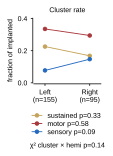

Wrote /hpc/group/coganlab/nanlinshi/insula-functional/img/grant_nmf_30subjects/fig2/fig2_laterality_cluster_rate.svg


/hpc/home/ns458/coganlab/nanlinshi/tmp/ipykernel_633754/2075771756.py:151: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [18]:
import pathlib

from scipy.stats import chi2_contingency, fisher_exact

from src.connectivity.pairwise.config import DEFAULT_DATASETS
from src.nmf.waveform_pca import load_exclude_channels
from src.paths import nmf_exclude_channels_path


def _as_bool_mix(values: pd.Series) -> pd.Series:
    if values.dtype == bool:
        return values
    text = values.astype(str).str.strip().str.lower()
    return text.isin({"1", "true", "t", "yes"})


def load_implanted_insula() -> pd.DataFrame:
    """Unique pure AIC/PIC bipolar contacts across the four NMF tasks."""
    frames = []
    for task, bids_root in DEFAULT_DATASETS.items():
        if task == "LexicalNoDelay":
            continue
        root = pathlib.Path(bids_root)
        paths = sorted(root.glob("derivatives/parcellation/sub-*/bipolar/sub-*_hammers.csv"))
        for path in paths:
            if path.parent.parent.name.removeprefix('sub-') not in SELECTED_SUBJECTS:
                continue
            df = pd.read_csv(path, usecols=lambda c: c in {"name", "roi", "hemi", "mix"})
            if not {"name", "roi", "hemi"}.issubset(df.columns):
                continue
            df = df.copy()
            df["subject"] = path.parent.parent.name.removeprefix("sub-")
            df["channel"] = df["name"].astype(str)
            frames.append(df)
    if not frames:
        raise FileNotFoundError("No Hammers parcellation CSVs in DEFAULT_DATASETS")
    allc = pd.concat(frames, ignore_index=True)
    if "mix" in allc.columns:
        allc["mix"] = _as_bool_mix(allc["mix"].fillna(False))
    else:
        allc["mix"] = False
    allc["hemi"] = allc["hemi"].astype(str).str.upper().str[0]
    uniq = allc.drop_duplicates(["subject", "channel"], keep="first")
    uniq = uniq[~uniq["subject"].isin(EXCLUDE_SUBJECTS)]
    implanted = uniq[uniq["roi"].astype(str).isin({"AIC", "PIC"}) & ~uniq["mix"]].copy()
    return implanted[implanted["hemi"].isin(["L", "R"])].reset_index(drop=True)


drop = load_exclude_channels(nmf_exclude_channels_path())
assign_lr = assignments.copy()
assign_lr["channel"] = assign_lr["channel"].astype(str)
assign_lr = assign_lr[~assign_lr["channel"].isin(drop)]
assign_lr = assign_lr[~assign_lr["subject"].astype(str).isin(EXCLUDE_SUBJECTS)]
assign_lr["hemi"] = assign_lr["hemi"].astype(str).str.upper().str[0]
assign_lr = assign_lr[assign_lr["hemi"].isin(["L", "R"])]
assign_lr = assign_lr[assign_lr["functional_cluster"].isin(CLUSTERS)]

implanted = load_implanted_insula()
n_imp = implanted.groupby("hemi").size()
n_cluster = (
    assign_lr.groupby(["functional_cluster", "hemi"])
    .size()
    .unstack(fill_value=0)
    .reindex(index=CLUSTERS, columns=["L", "R"], fill_value=0)
)
n_rate = n_cluster.div(n_imp, axis=1)

n_imp_l = int(n_imp["L"])
n_imp_r = int(n_imp["R"])


def _fmt_p(p: float) -> str:
    if p < 0.001:
        return "p<0.001"
    return f"p={p:.2f}"


fisher_p = {}
for cluster in CLUSTERS:
    n_l = int(n_cluster.loc[cluster, "L"])
    n_r = int(n_cluster.loc[cluster, "R"])
    table = [
        [n_l, n_r],
        [n_imp_l - n_l, n_imp_r - n_r],
    ]
    _, fisher_p[cluster] = fisher_exact(table, alternative="two-sided")
_, p_chi, _, _ = chi2_contingency(n_cluster.to_numpy())

print(f"implanted AIC/PIC  L={n_imp_l}  R={n_imp_r}")
print("assigned n")
print(n_cluster.to_string())
print("rate = assigned / implanted")
print(n_rate.round(3).to_string())
print("Fisher exact  assigned vs not × L vs R")
for cluster in CLUSTERS:
    print(f"  {CLUSTER_LABELS[cluster]:10s}  {_fmt_p(fisher_p[cluster])}")
print(f"χ² cluster × hemi  {_fmt_p(p_chi)}")

fig, ax = plt.subplots(figsize=(3.6 * cm, 5.2 * cm))
x = np.array([0.0, 1.0])
for cluster in CLUSTERS:
    color = FUNCTION_COLORS[cluster]
    label = CLUSTER_LABELS[cluster]
    y_l = float(n_rate.loc[cluster, "L"])
    y_r = float(n_rate.loc[cluster, "R"])
    ax.plot(
        x,
        [y_l, y_r],
        "-o",
        color=color,
        ms=3.5,
        lw=0.9,
        label=f"{label}  {_fmt_p(fisher_p[cluster])}",
    )

ax.set_ylabel("fraction of implanted", fontsize=fontsize)
ax.set_title("Cluster rate", fontsize=fontsize)
hemi_tick = [
    f"Left\n(n={n_imp_l})",
    f"Right\n(n={n_imp_r})",
]
ax.set_xticks(x)
ax.set_xticklabels(hemi_tick)
ax.set_xlim(-0.25, 1.25)
ax.set_ylim(0, max(0.4, float(n_rate.to_numpy().max()) * 1.2))
ax.tick_params(labelsize=fontsize, width=0.75, length=2, which="both")
plt.setp(ax.spines.values(), linewidth=0.75)
sns.despine(ax=ax, offset=1, trim=False)
ax.legend(
    frameon=False,
    fontsize=fontsize,
    loc="upper center",
    ncol=1,
    bbox_to_anchor=(0.5, -0.42),
    handlelength=1.4,
    borderaxespad=0.0,
    labelspacing=0.25,
)
ax.text(
    0.5,
    -0.92,
    f"χ² cluster × hemi  {_fmt_p(p_chi)}",
    transform=ax.transAxes,
    ha="center",
    va="top",
    fontsize=fontsize,
    clip_on=False,
)
fig.subplots_adjust(left=0.30, right=0.96, bottom=0.46, top=0.90)
out = save_svg(fig, IMG_DIR / "fig2_laterality_cluster_rate.svg")
plt.show()
print("Wrote", out)
assert set(implanted.subject).issubset(SELECTED_SUBJECTS)
assert set(assign_lr.subject) == SELECTED_SUBJECTS
implanted.to_csv(NMF_DIR/'implanted_insula_30subjects.csv',index=False)
n_cluster.to_csv(NMF_DIR/'laterality_cluster_counts.csv')
n_rate.to_csv(NMF_DIR/'laterality_cluster_rates.csv')
(NMF_DIR/'laterality_stats.json').write_text(json.dumps(dict(implanted=n_imp.to_dict(), fisher_p=fisher_p, chi_square_p=p_chi),indent=2))

plt.close("all")


## 10. Cluster-weighted density

RGB mix of sensory / sustain / motor colors on the insula pial, weighted by loading specificity (`s_k = max(p_k − max_{j≠k} p_j, 0)`) for **all** discovery electrodes. Mixed contacts barely paint; they are gray foci (`specificity_max` = winner − runner-up `< 0.20`, same as §7), not a gray density channel. This is not parcel mix (Hammers AIC/PIC overlap).


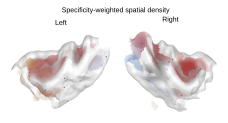

Wrote /hpc/group/coganlab/nanlinshi/insula-functional/img/grant_nmf_30subjects/fig2/fig2_cluster_density.svg


/hpc/home/ns458/coganlab/nanlinshi/tmp/ipykernel_633754/1463007716.py:221: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [19]:
import warnings

import matplotlib.colors as mcolors
from matplotlib.patches import Patch
from scipy.spatial.distance import cdist

# Surface Gaussian kernel (same as functional_hga_specificity spatial density).
DENSITY_BANDWIDTH = 5.0
DENSITY_MAX_DISTANCE = 6.0
CLUSTER_RGB = np.array(
    [mcolors.to_rgb(FUNCTION_COLORS[name]) for name in CLUSTERS],
    dtype=float,
)

if "is_mixed" not in assignments.columns:
    assignments = annotate_mixed_assignments(assignments)

frame = assignments.loc[
    assignments["functional_cluster"].isin(CLUSTERS)
    & ~assignments["subject"].isin(EXCLUDE_SUBJECTS)
    & assignments[["x", "y", "z"]].notna().all(axis=1)
].copy()


def make_insula_brains():
    """§7 brains: hidden cortex + pale insula mesh."""
    brains = []
    for hemi in ("lh", "rh"):
        brain = Brain(
            template,
            subjects_dir=recon_dir,
            surf="pial",
            hemi=hemi,
            background="white",
            show=False,
            cortex=INSULA_COLOR,
            alpha=0.0,
            size=(800, 800),
        )
        mesh = lh_insula if hemi == "lh" else rh_insula
        brain._renderer.plotter.add_mesh(
            mesh,
            color=INSULA_COLOR,
            opacity=INSULA_LABEL_ALPHA,
            lighting=True,
            smooth_shading=True,
        )
        brains.append(brain)
    return brains[0], brains[1]


def add_foci(brain, coords, tree, pial_coords, *, color, point_size=9.0):
    if len(coords) == 0:
        return
    _, indices = tree.query(coords)
    cloud = pv.PolyData(np.asarray(pial_coords[indices], dtype=float))
    brain._renderer.plotter.add_mesh(
        cloud,
        render_points_as_spheres=True,
        point_size=float(point_size),
        color=color,
        lighting=False,
    )


def compute_cluster_densities(
    surface_coords: np.ndarray,
    electrode_coords: np.ndarray,
    weights: np.ndarray,
    *,
    bandwidth: float = DENSITY_BANDWIDTH,
    max_distance: float = DENSITY_MAX_DISTANCE,
) -> np.ndarray:
    """Return ``(n_vertices, n_clusters)`` Gaussian densities."""
    n_vertices = len(surface_coords)
    n_clusters = weights.shape[1] if len(weights) else len(CLUSTERS)
    dens = np.zeros((n_vertices, n_clusters), dtype=float)
    if len(electrode_coords) == 0:
        return dens
    weights = np.clip(np.asarray(weights, dtype=float), 0.0, None)
    distances = cdist(surface_coords, electrode_coords)
    near = distances.min(axis=1) < max_distance
    if not near.any():
        return dens
    kernel = np.exp(-distances[near] ** 2 / (2.0 * bandwidth ** 2))
    dens[near] = kernel @ weights
    return dens


def densities_to_rgba(
    dens: np.ndarray,
    colors_rgb: np.ndarray = CLUSTER_RGB,
    *,
    alpha_percentile: float = 95.0,
) -> np.ndarray:
    total = dens.sum(axis=1)
    mix = np.zeros_like(dens)
    nonzero = total > 0
    mix[nonzero] = dens[nonzero] / total[nonzero, None]
    rgb = mix @ colors_rgb
    alpha = np.zeros(len(total), dtype=float)
    if nonzero.any():
        scale = float(np.percentile(total[nonzero], alpha_percentile))
        alpha = np.clip(total / max(scale, 1e-12), 0.0, 1.0)
    return np.concatenate([rgb, alpha[:, None]], axis=1)


def add_density_rgba_mesh(
    brain, hemi: str, pial_coords: np.ndarray, rgba: np.ndarray
) -> None:
    faces = np.asarray(brain.geo[hemi].faces, dtype=np.int64)
    cells = np.hstack(
        [np.full((len(faces), 1), 3, dtype=np.int64), faces]
    ).ravel()
    mesh = pv.PolyData(np.asarray(pial_coords, dtype=float), cells)
    mesh["rgba"] = (np.clip(rgba, 0.0, 1.0) * 255.0).astype(np.uint8)
    brain._renderer.plotter.add_mesh(
        mesh,
        scalars="rgba",
        rgba=True,
        lighting=False,
        smooth_shading=True,
    )


def cluster_density_weights(frame: pd.DataFrame) -> np.ndarray:
    """(n_electrodes, 3) specificity s_k in CLUSTERS / CLUSTER_RGB order.

    Do not use raw proportions: mixed AIC contacts still carry motor p,
    which reddens the RGB mix. Multiply by HGA only if that column exists.
    """
    missing = [c for c in LOADING_COLS if c not in frame.columns]
    if missing:
        raise KeyError(f"assignments missing {missing}")
    _, spec = specificity_from_loadings(frame[LOADING_COLS].to_numpy())
    if "HGA" in frame.columns:
        hga = np.clip(frame["HGA"].to_numpy(dtype=float), 0.0, None)
        return spec * hga[:, None]
    return spec


def render_cluster_density(frame: pd.DataFrame):
    lh_brain, rh_brain = make_insula_brains()
    cord = frame[["x", "y", "z"]].to_numpy(float)
    weights = cluster_density_weights(frame)
    mask_lh = cord[:, 0] < 0
    mask_rh = cord[:, 0] > 0
    dens_lh = compute_cluster_densities(
        lh_pial_coords, cord[mask_lh], weights[mask_lh]
    )
    dens_rh = compute_cluster_densities(
        rh_pial_coords, cord[mask_rh], weights[mask_rh]
    )
    add_density_rgba_mesh(
        lh_brain, "lh", lh_pial_coords, densities_to_rgba(dens_lh, CLUSTER_RGB)
    )
    add_density_rgba_mesh(
        rh_brain, "rh", rh_pial_coords, densities_to_rgba(dens_rh, CLUSTER_RGB)
    )
    is_mixed = frame["is_mixed"].to_numpy()
    add_foci(
        lh_brain,
        cord[mask_lh & is_mixed],
        lh_tree,
        lh_pial_coords,
        color=MIXED_COLOR,
        point_size=8,
    )
    add_foci(
        rh_brain,
        cord[mask_rh & is_mixed],
        rh_tree,
        rh_pial_coords,
        color=MIXED_COLOR,
        point_size=8,
    )
    lh_brain.show_view(
        azimuth=180, elevation=90, distance=180, focalpoint=lh_insula_center
    )
    rh_brain.show_view(
        azimuth=0, elevation=90, distance=180, focalpoint=rh_insula_center
    )
    for _ in range(3):
        lh_brain._renderer.plotter.render()
        rh_brain._renderer.plotter.render()
    lh_img = np.asarray(lh_brain.screenshot(mode="rgb"))
    rh_img = np.asarray(rh_brain.screenshot(mode="rgb"))
    lh_brain.close()
    rh_brain.close()
    return lh_img, rh_img


with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    dens_lh, dens_rh = render_cluster_density(frame)

dens_lh, _ = crop_to_content(dens_lh, np.zeros((0, 2)))
dens_rh, _ = crop_to_content(dens_rh, np.zeros((0, 2)))

fig, axes = plt.subplots(1, 2, figsize=(8 * cm, 4 * cm))
axes[0].imshow(dens_lh)
axes[0].axis("off")
axes[0].set_title("Left", fontsize=fontsize)
axes[1].imshow(dens_rh)
axes[1].axis("off")
axes[1].set_title("Right", fontsize=fontsize)
legend_elements = [
    Patch(facecolor=FUNCTION_COLORS[name], label=CLUSTER_LABELS[name])
    for name in CLUSTERS
]
legend_elements.append(Patch(facecolor=MIXED_COLOR, label="mixed"))
# axes[0].legend(
#     handles=legend_elements,
#     loc="upper left",
#     fontsize=fontsize - 1,
#     framealpha=0.9,
# )
fig.suptitle("Specificity-weighted spatial density", fontsize=fontsize)
fig.subplots_adjust(wspace=0.02, left=0.02, right=0.98, top=0.80, bottom=0.02)
out = save_svg(fig, IMG_DIR / "fig2_cluster_density.svg")
plt.show()
print("Wrote", out)

plt.close("all")


In [20]:
import xml.etree.ElementTree as ET
from datetime import datetime, timezone
expected = {
 'fig2_insula_average_traces.svg','fig2_nmf_traces.svg','fig2_hga_traces.svg',
 'fig2_hga_heatmap.svg','fig2_nmf_rank_k.svg','fig2_waveform_pca_kmeans.svg',
 'fig2_nmf_dominance.svg','fig2_insula_spatial_kdecontour.svg',
 'fig2_nmf_weight_density_sensory.svg','fig2_nmf_weight_density_sustain.svg',
 'fig2_nmf_weight_density_motor.svg','fig2_nmf_weight_density_all.svg',
 'fig2_insula_cluster_parcel_pies.svg','fig2_insula_cluster_parcel_pies_k6.svg',
 'fig2_laterality_cluster_rate.svg','fig2_cluster_density.svg'}
assert {p['filename'] for p in FIG2_PANELS} == expected
for panel in FIG2_PANELS:
    path=IMG_DIR/panel['filename']
    root=ET.parse(path).getroot()
    panel['svg_cm']=[float(root.attrib[k].removesuffix('pt'))*2.54/72 for k in ('width','height')]
    assert panel['svg_cm'][0] <= 18
    panel['sha256']=hashlib.sha256(path.read_bytes()).hexdigest()
    if panel['filename'] in ('fig2_insula_average_traces.svg','fig2_nmf_traces.svg','fig2_hga_traces.svg'):
        assert np.allclose(panel['svg_cm'],[8,3])
        assert 'Go' not in [t.text for t in root.iter('{http://www.w3.org/2000/svg}text')]
validation=dict(completed_utc=datetime.now(timezone.utc).isoformat(),slurm_job=os.getenv('SLURM_JOB_ID'),
    reference='vizpub/fig2.ipynb',n_subjects=30,n_electrodes=157,n_features=572,
    fixed_nmf_k=3,rank_recommendation=json.loads((NMF_DIR/'chosen_k.json').read_text()),
    display_phases=TRACE_PHASES,fit_response_window=[-.5,1.],nmf_sha256=fit_hash,
    empirical_summary='Figure 2 pooled trial-averaged HGA rows, mean and bootstrap 95% CI',
    heatmap_rows='bipolar electrodes; significance masked; first significant time ordering per phase',
    subjects=sorted(SELECTED_SUBJECTS),figures=FIG2_PANELS)
(NMF_DIR/'validation.json').write_text(json.dumps(validation,indent=2))
pd.DataFrame(FIG2_PANELS).to_csv(NMF_DIR/'figure_index.csv',index=False)
print('Validated all 16 Figure 2 panels for 30 subjects / 157 electrodes.')


Validated all 16 Figure 2 panels for 30 subjects / 157 electrodes.
